In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
np.random.seed(SEED)
N_JOBS = -1

DATA_FILE = "networkTraffic.csv"
TARGET = "attack_cat"
NOMINAL = ["proto", "service", "state"]
CLASS_NAMES = ["Normal", "Reconnaissance", "Backdoor", "DoS", "Exploits",
               "Analysis", "Fuzzers", "Worms", "Shellcode", "Generic"]
N_CLASSES = len(CLASS_NAMES)
NORMAL = 0
WORMS = 7

TEST_SIZE = 20000
TUNE_SIZE = 80000
TUNE_FOLDS = 5
EVAL_FOLDS = 10
TEST_RUNS = 10

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)


plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 10, "axes.labelsize": 10, "legend.fontsize": 10,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 1.5, "lines.markersize": 4,
    "figure.figsize": (3.45, 2.3), "savefig.bbox": "tight", "savefig.dpi": 400,
})
COLOURS = {"forest": "0.10", "tree": "0.55", "knn": "0.35", "grey": "0.50"}

In [2]:
data = pd.read_csv(DATA_FILE, na_values="?")
print("observations:", data.shape[0], "| columns:", data.shape[1])

data = data.drop(columns=["id"])
print("missing service values:", round(100 * data["service"].isna().mean(), 1), "%")
data["service"] = data["service"].fillna("missing")

X_all = data.drop(columns=[TARGET])
y_all = data[TARGET].to_numpy()
NUMERIC = [c for c in X_all.columns if c not in NOMINAL]
print(len(NUMERIC), "numerical and", len(NOMINAL), "nominal descriptive features")

observations: 257673 | columns: 44
missing service values: 54.8 %
39 numerical and 3 nominal descriptive features


In [3]:
counts = np.bincount(y_all, minlength=N_CLASSES)
class_table = pd.DataFrame({"class": CLASS_NAMES, "count": counts,
                            "percent": np.round(100 * counts / len(y_all), 2)})
print(class_table.to_string(index=False))
print("imbalance ratio:", round(counts.max() / counts.min()), "to one")

for c in NOMINAL:
    levels = X_all[c].value_counts()
    print(f"{c}: {len(levels)} levels, {(levels >= 500).sum()} levels with at least 500 observations")

         class  count  percent
        Normal  93000    36.09
Reconnaissance  13987     5.43
      Backdoor   2329     0.90
           DoS  16353     6.35
      Exploits  44525    17.28
      Analysis   2677     1.04
       Fuzzers  24246     9.41
         Worms    174     0.07
     Shellcode   1511     0.59
       Generic  58871    22.85
imbalance ratio: 534 to one
proto: 133 levels, 6 levels with at least 500 observations
service: 13 levels, 8 levels with at least 500 observations
state: 11 levels, 4 levels with at least 500 observations


In [4]:
vector = pd.util.hash_pandas_object(X_all, index=False).to_numpy()
groups = pd.DataFrame({"vector": vector, "label": y_all})

copies = data.duplicated().sum()
labels_per_vector = groups.groupby("vector")["label"].transform("nunique").to_numpy()
conflicting = labels_per_vector > 1

print("distinct feature vectors:", groups["vector"].nunique())
print("exact duplicate rows:", copies, f"({100 * copies / len(data):.1f} %)")
print("rows whose feature vector also occurs with another label:", conflicting.sum(),
      f"({100 * conflicting.mean():.1f} %)")


majority = groups.groupby("vector")["label"].agg(lambda s: s.value_counts().index[0])
best_possible = groups["vector"].map(majority).to_numpy()
print("attainable accuracy:", round(accuracy_score(y_all, best_possible), 4))
print("attainable macro F1:", round(f1_score(y_all, best_possible, average="macro"), 4))

attainable = pd.DataFrame({
    "class": CLASS_NAMES,
    "conflicting_share": [conflicting[y_all == c].mean() for c in range(N_CLASSES)],
    "attainable_f1": f1_score(y_all, best_possible, average=None),
})
print(attainable.round(3).to_string(index=False))
attainable.to_csv("results/attainable.csv", index=False)

distinct feature vectors: 153684
exact duplicate rows: 94928 (36.8 %)
rows whose feature vector also occurs with another label: 40400 (15.7 %)


attainable accuracy: 0.9139
attainable macro F1: 0.7774
         class  conflicting_share  attainable_f1
        Normal              0.010          0.996
Reconnaissance              0.161          0.914
      Backdoor              0.849          0.265
           DoS              0.774          0.539
      Exploits              0.371          0.812
      Analysis              0.770          0.375
       Fuzzers              0.149          0.924
         Worms              0.086          0.957
     Shellcode              0.009          0.996
       Generic              0.006          0.997


In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
X_tune, X_eval, y_tune, y_eval = train_test_split(
    X_dev, y_dev, train_size=TUNE_SIZE, stratify=y_dev, random_state=SEED)

for name, y in [("development", y_dev), ("tuning", y_tune), ("evaluation", y_eval), ("test", y_test)]:
    print(f"{name:12s} {len(y):7d} observations, {np.sum(y == WORMS):4d} Worms")


dev_vectors = set(pd.util.hash_pandas_object(X_dev, index=False))
test_vectors = pd.util.hash_pandas_object(X_test, index=False)
print("test observations with an identical feature vector in the development partition:",
      f"{100 * test_vectors.isin(dev_vectors).mean():.1f} %")

development   237673 observations,  160 Worms
tuning         80000 observations,   54 Worms
evaluation    157673 observations,  106 Worms
test           20000 observations,   14 Worms


test observations with an identical feature vector in the development partition: 46.4 %


In [6]:
def frequent_levels(X, min_share):
    levels = {}
    for column in NOMINAL:
        shares = X[column].value_counts(normalize=True)
        levels[column] = shares[shares >= min_share].index
    return levels


def one_hot(X_fit, X_apply, min_share):
    levels = frequent_levels(X_fit, min_share)

    def encode(X):
        nominal = X[NOMINAL].copy()
        for column in NOMINAL:
            nominal[column] = nominal[column].where(
                nominal[column].isin(levels[column]), "other"
            )
        return pd.get_dummies(nominal, dtype=float)

    fit_encoded = encode(X_fit)
    apply_encoded = encode(X_apply).reindex(
        columns=fit_encoded.columns, fill_value=0.0
    )
    return fit_encoded.to_numpy(), apply_encoded.to_numpy()


def tree_inputs(X_fit, X_apply, min_share):
    fit_encoded, apply_encoded = one_hot(X_fit, X_apply, min_share)
    fit_numeric = X_fit[NUMERIC].to_numpy(float)
    apply_numeric = X_apply[NUMERIC].to_numpy(float)
    return (
        np.hstack([fit_numeric, fit_encoded]),
        np.hstack([apply_numeric, apply_encoded]),
    )


KNN_NUMERIC = ["smean", "sload", "dmean", "rate", "ct_dst_sport_ltm"]
KNN_SHARE = 0.0025


def knn_inputs(X_fit, X_apply, min_share=KNN_SHARE):
    fit_numeric = np.log1p(X_fit[KNN_NUMERIC])
    apply_numeric = np.log1p(X_apply[KNN_NUMERIC])
    scaler = StandardScaler().fit(fit_numeric)
    fit_encoded, apply_encoded = one_hot(X_fit, X_apply, min_share)
    return (
        np.hstack([scaler.transform(fit_numeric), fit_encoded]),
        np.hstack([scaler.transform(apply_numeric), apply_encoded]),
    )

In [7]:
def make_knn():
    return KNeighborsClassifier(
        n_neighbors=11,
        metric="manhattan",
        weights="distance",
        n_jobs=N_JOBS,
    )


def make_tree(max_depth=14):
    return DecisionTreeClassifier(
        criterion="gini", max_depth=max_depth, random_state=SEED
    )


def class_weights(y, gamma):
    counts = np.bincount(y, minlength=N_CLASSES)
    weights = (len(y) / (N_CLASSES * counts)) ** gamma
    return {label: weights[label] for label in range(N_CLASSES)}


def make_forest(
    y_fit,
    n_trees=100,
    m="sqrt",
    max_depth=None,
    bag=None,
    gamma=0.0,
    seed=SEED,
):
    return RandomForestClassifier(
        n_estimators=n_trees,
        criterion="gini",
        max_features=m,
        max_depth=max_depth,
        bootstrap=True,
        max_samples=bag,
        class_weight=class_weights(y_fit, gamma),
        n_jobs=N_JOBS,
        random_state=seed,
    )

In [8]:
def scores(y_true, y_pred):
    row = {
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }
    per_class = f1_score(
        y_true, y_pred, average=None, labels=range(N_CLASSES), zero_division=0
    )
    for name, value in zip(CLASS_NAMES, per_class):
        row["f1_" + name] = value
    return row


def make_folds(X, y, n_folds, inputs):
    splitter = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    folds = []
    for train_index, valid_index in splitter.split(X, y):
        train_inputs, valid_inputs = inputs(X.iloc[train_index], X.iloc[valid_index])
        folds.append((train_inputs, y[train_index], valid_inputs, y[valid_index]))
    return folds


def run_cv(make_model, folds, train_scores=False):
    rows = []
    for train_inputs, train_labels, valid_inputs, valid_labels in folds:
        model = make_model(train_labels)
        start = time.time()
        model.fit(train_inputs, train_labels)
        fit_time = time.time() - start

        row = scores(valid_labels, model.predict(valid_inputs))
        row["fit_time"] = fit_time
        if train_scores:
            sample = np.random.RandomState(SEED).choice(
                len(train_labels), 10000, replace=False
            )
            row["train_macro_f1"] = f1_score(
                train_labels[sample], model.predict(train_inputs[sample]), average="macro"
            )
        rows.append(row)
    return pd.DataFrame(rows)


def summarise(results, setting):
    summary = {"setting": setting}
    for column in results.columns:
        summary[column + "_mean"] = results[column].mean()
        summary[column + "_std"] = results[column].std(ddof=1)
    return summary


def one_se_choice(table, n_folds, measure="macro_f1"):
    means = table[measure + "_mean"]
    best_index = means.idxmax()
    standard_error = table.loc[best_index, measure + "_std"] / np.sqrt(n_folds)
    threshold = means.loc[best_index] - standard_error
    return table.loc[means >= threshold, "setting"].iloc[0]


SHOW = [
    "setting", "macro_f1_mean", "macro_f1_std", "mcc_mean",
    "f1_Worms_mean", "fit_time_mean",
]

In [9]:
THRESHOLDS = [0.025, 0.0025, 0.00025, 0]
q0 = []
for share in THRESHOLDS:
    folds = make_folds(X_tune, y_tune, TUNE_FOLDS, lambda a, b: tree_inputs(a, b, share))
    forest = run_cv(lambda y: make_forest(y), folds)
    tree = run_cv(lambda y: make_tree(), folds)
    q0.append({"setting": share, "p": folds[0][0].shape[1],
               "macro_f1_mean": forest["macro_f1"].mean(), "macro_f1_std": forest["macro_f1"].std(),
               "f1_Worms_mean": forest["f1_Worms"].mean(),
               "tree_macro_f1_mean": tree["macro_f1"].mean(), "tree_macro_f1_std": tree["macro_f1"].std()})
q0 = pd.DataFrame(q0)
print(q0.round(4).to_string(index=False))
q0.to_csv("results/q0_grouping.csv", index=False)

MIN_SHARE = float(one_se_choice(q0, TUNE_FOLDS))
print("selected grouping threshold:", MIN_SHARE)

 setting   p  macro_f1_mean  macro_f1_std  f1_Worms_mean  tree_macro_f1_mean  tree_macro_f1_std
  0.0250  52         0.5507        0.0064         0.3130              0.5624             0.0131
  0.0025  60         0.5447        0.0085         0.2643              0.5594             0.0112
  0.0002 188         0.5242        0.0133         0.1282              0.5582             0.0123
  0.0000 192         0.5218        0.0124         0.1030              0.5579             0.0130
selected grouping threshold: 0.025


In [10]:
tune_folds = make_folds(X_tune, y_tune, TUNE_FOLDS, lambda a, b: tree_inputs(a, b, MIN_SHARE))
P = tune_folds[0][0].shape[1]
print("number of features after encoding, p =", P, "| default subspace size =", int(np.sqrt(P)))


tree_ref = run_cv(lambda y: make_tree(), tune_folds)
print("assignment 2 tree: macro F1", round(tree_ref["macro_f1"].mean(), 4), "+-",
      round(tree_ref["macro_f1"].std(), 4), "| MCC", round(tree_ref["mcc"].mean(), 4))

number of features after encoding, p = 52 | default subspace size = 7


assignment 2 tree: macro F1 0.5624 +- 0.0131 | MCC 0.7516


In [11]:
CHECKPOINTS = [1, 2, 5, 10, 20, 50, 100, 150, 200, 300]


def staged_macro_f1(forest, A, y_a, B, y_b):


    n, k = len(y_a), len(forest.classes_)
    valid_total, oob_total, oob_trees = np.zeros((len(B), k)), np.zeros((n, k)), np.zeros(n)
    rows = []
    for b, (tree, drawn) in enumerate(zip(forest.estimators_, forest.estimators_samples_), start=1):
        valid_total += tree.predict_proba(B)
        left_out = np.bincount(drawn, minlength=n) == 0
        oob_total[left_out] += tree.predict_proba(A[left_out])
        oob_trees[left_out] += 1
        if b in CHECKPOINTS:
            scored = oob_trees > 0
            rows.append({"setting": b,
                         "macro_f1": f1_score(y_b, forest.classes_[valid_total.argmax(axis=1)], average="macro"),
                         "oob_macro_f1": f1_score(y_a[scored], forest.classes_[oob_total[scored].argmax(axis=1)],
                                                  average="macro"),
                         "oob_scored": scored.mean()})
    scored = oob_trees > 0
    per_class = pd.DataFrame({
        "cv_f1": f1_score(y_b, forest.classes_[valid_total.argmax(axis=1)], average=None,
                          labels=range(N_CLASSES), zero_division=0),
        "oob_f1": f1_score(y_a[scored], forest.classes_[oob_total[scored].argmax(axis=1)], average=None,
                           labels=range(N_CLASSES), zero_division=0),
        "left_out_share": [oob_trees[y_a == c].mean() / len(forest.estimators_) for c in range(N_CLASSES)]},
        index=CLASS_NAMES)
    return pd.DataFrame(rows), per_class


def ensemble_size_curve(make_model, folds):


    curves, classes = [], []
    for A, y_a, B, y_b in folds:
        curve, per_class = staged_macro_f1(make_model(y_a).fit(A, y_a), A, y_a, B, y_b)
        curves.append(curve)
        classes.append(per_class)
    table = pd.concat(curves).groupby("setting").agg(["mean", "std"])
    table.columns = [f"{measure}_{stat}" for measure, stat in table.columns]
    return table.reset_index(), sum(classes) / len(classes)


q1_default, q1_default_classes = ensemble_size_curve(lambda y: make_forest(y, n_trees=max(CHECKPOINTS)),
                                                     tune_folds)
print(q1_default.round(4).to_string(index=False))
q1_default.to_csv("results/q1_trees_default.csv", index=False)

N_TREES = int(one_se_choice(q1_default, TUNE_FOLDS))
print("ensemble size used in Q2 to Q4:", N_TREES)

 setting  macro_f1_mean  macro_f1_std  oob_macro_f1_mean  oob_macro_f1_std  oob_scored_mean  oob_scored_std
       1         0.4870        0.0034             0.4861            0.0095           0.3680             0.0
       2         0.4719        0.0137             0.4850            0.0063           0.6017             0.0
       5         0.5173        0.0091             0.4931            0.0054           0.9002             0.0
      10         0.5302        0.0114             0.5114            0.0022           0.9905             0.0
      20         0.5405        0.0139             0.5293            0.0041           0.9999             0.0
      50         0.5521        0.0085             0.5412            0.0028           1.0000             0.0
     100         0.5507        0.0064             0.5439            0.0036           1.0000             0.0
     150         0.5525        0.0096             0.5460            0.0062           1.0000             0.0
     200         0.5504     

In [12]:
A, y_a, B, y_b = tune_folds[0]
two_trees = make_forest(y_a, n_trees=2).fit(A, y_a)
top_two = np.sort(two_trees.predict_proba(B), axis=1)[:, -2:]
print("validation records with a tie between two classes:",
      round(100 * np.mean(top_two[:, 0] == top_two[:, 1]), 1), "%")

validation records with a tie between two classes: 13.4 %


In [13]:
DEPTHS = [2, 4, 6, 8, 10, 12, 14, 16, 20, 25, None]
q2_forest, q2_tree = [], []
for depth in DEPTHS:
    setting = "unlimited" if depth is None else depth
    forest = run_cv(lambda y: make_forest(y, n_trees=N_TREES, max_depth=depth), tune_folds, train_scores=True)
    tree = run_cv(lambda y: make_tree(max_depth=depth), tune_folds, train_scores=True)
    q2_forest.append(summarise(forest, setting))
    q2_tree.append(summarise(tree, setting))
q2_forest, q2_tree = pd.DataFrame(q2_forest), pd.DataFrame(q2_tree)

cols = ["setting", "macro_f1_mean", "macro_f1_std", "train_macro_f1_mean", "mcc_mean", "f1_Worms_mean"]
print("forest\n", q2_forest[cols].round(4).to_string(index=False))
print("tree\n", q2_tree[cols].round(4).to_string(index=False))
q2_forest.to_csv("results/q2_depth_forest.csv", index=False)
q2_tree.to_csv("results/q2_depth_tree.csv", index=False)

MAX_DEPTH = one_se_choice(q2_forest, TUNE_FOLDS)
MAX_DEPTH = None if MAX_DEPTH == "unlimited" else int(MAX_DEPTH)
print("selected maximum depth of the forest:", MAX_DEPTH)
print("best depth of the single tree:", q2_tree.loc[q2_tree["macro_f1_mean"].idxmax(), "setting"])

forest
   setting  macro_f1_mean  macro_f1_std  train_macro_f1_mean  mcc_mean  f1_Worms_mean
        2         0.2015        0.0009               0.2013    0.5024         0.0000
        4         0.2976        0.0026               0.2986    0.6713         0.0000
        6         0.3470        0.0049               0.3474    0.7145         0.0000
        8         0.3878        0.0064               0.3925    0.7411         0.0000
       10         0.4409        0.0067               0.4622    0.7547         0.0000
       12         0.4897        0.0100               0.5516    0.7627         0.1005
       14         0.5218        0.0119               0.6036    0.7654         0.2282
       16         0.5328        0.0089               0.6546    0.7670         0.2256
       20         0.5411        0.0168               0.7616    0.7668         0.2154
       25         0.5443        0.0129               0.7974    0.7624         0.2462
unlimited         0.5521        0.0085               0.80

In [14]:
A, y_a, B, y_b = tune_folds[0]
forest = make_forest(y_a, n_trees=N_TREES).fit(A, y_a)
tree = make_tree().fit(A, y_a)
print("forest trees: mean depth", np.mean([t.get_depth() for t in forest.estimators_]),
      "| mean leaves", np.mean([t.get_n_leaves() for t in forest.estimators_]))
print("depth-14 tree: leaves", tree.get_n_leaves())

forest trees: mean depth 40.5 | mean leaves 5884.74
depth-14 tree: leaves 937


In [15]:
def strength_and_diversity(forest, B, y_b, n_trees=50):

    votes = np.array([forest.classes_[t.predict(B).astype(int)] for t in forest.estimators_[:n_trees]])
    strength = np.mean([f1_score(y_b, v, average="macro") for v in votes])
    disagreement = np.mean([np.mean(votes[i] != votes[j])
                            for i in range(len(votes)) for j in range(i + 1, len(votes))])
    return strength, disagreement


M_VALUES = [1, 2, 4, int(np.sqrt(P)), P // 4, P // 2, 3 * P // 4, P]
q3_m = []
for m in M_VALUES:
    rows = []
    for A, y_a, B, y_b in tune_folds:
        forest = make_forest(y_a, n_trees=N_TREES, m=m, max_depth=MAX_DEPTH)
        start = time.time()
        forest.fit(A, y_a)
        fit_time = time.time() - start
        row = scores(y_b, forest.predict(B))
        row["strength"], row["disagreement"] = strength_and_diversity(forest, B, y_b)
        row["fit_time"] = fit_time
        rows.append(row)
    q3_m.append(summarise(pd.DataFrame(rows), m))
q3_m = pd.DataFrame(q3_m)
print(q3_m[SHOW + ["strength_mean", "disagreement_mean"]].round(4).to_string(index=False))
q3_m.to_csv("results/q3_subspace.csv", index=False)

M = int(one_se_choice(q3_m, TUNE_FOLDS))
print("selected subspace size m =", M)

 setting  macro_f1_mean  macro_f1_std  mcc_mean  f1_Worms_mean  fit_time_mean  strength_mean  disagreement_mean
       1         0.5061        0.0072    0.7530         0.0286         1.7318         0.4642             0.2120
       2         0.5119        0.0070    0.7567         0.0308         1.8517         0.4688             0.2075
       4         0.5265        0.0162    0.7585         0.1282         2.5092         0.4800             0.2001
       7         0.5521        0.0085    0.7612         0.3403         3.3953         0.4924             0.1935
      13         0.5514        0.0124    0.7635         0.2790         5.3346         0.5057             0.1879
      26         0.5638        0.0123    0.7637         0.3938        10.3392         0.5144             0.1842
      39         0.5732        0.0155    0.7631         0.4824        14.3698         0.5193             0.1821
      52         0.5653        0.0164    0.7612         0.4557        18.2877         0.5194            

In [16]:
BAG_VALUES = [0.1, 0.25, 0.5, 0.75, 1.0]
q3_bag = []
for bag in BAG_VALUES:
    fold_scores = run_cv(
        lambda y: make_forest(
            y, n_trees=N_TREES, m=M, max_depth=MAX_DEPTH, bag=bag
        ),
        tune_folds,
    )
    q3_bag.append(summarise(fold_scores, bag))

q3_bag = pd.DataFrame(q3_bag)
print(q3_bag[SHOW].round(4).to_string(index=False))
q3_bag.to_csv("results/q3_bag.csv", index=False)

BAG = float(one_se_choice(q3_bag, TUNE_FOLDS))
print("selected bag size:", BAG)

 setting  macro_f1_mean  macro_f1_std  mcc_mean  f1_Worms_mean  fit_time_mean
    0.10         0.5142        0.0138    0.7542         0.1238         1.9039
    0.25         0.5492        0.0117    0.7610         0.3237         4.2403
    0.50         0.5509        0.0157    0.7628         0.2947         8.1661
    0.75         0.5577        0.0149    0.7627         0.3414        11.3954
    1.00         0.5732        0.0155    0.7631         0.4824        14.3691
selected bag size: 1.0


In [17]:
GAMMAS = [0.0, 0.25, 0.5, 0.75, 1.0]
q4 = []
for gamma in GAMMAS:
    fold_scores = run_cv(
        lambda y: make_forest(
            y, n_trees=N_TREES, m=M, max_depth=MAX_DEPTH, bag=BAG, gamma=gamma
        ),
        tune_folds,
    )
    q4.append(summarise(fold_scores, gamma))

q4 = pd.DataFrame(q4)
columns = SHOW + ["macro_precision_mean", "macro_recall_mean", "f1_Normal_mean"]
print(q4[columns].round(4).to_string(index=False))
q4.to_csv("results/q4_weights.csv", index=False)

GAMMA = float(one_se_choice(q4, TUNE_FOLDS))
print("selected weighting exponent gamma =", GAMMA)

 setting  macro_f1_mean  macro_f1_std  mcc_mean  f1_Worms_mean  fit_time_mean  macro_precision_mean  macro_recall_mean  f1_Normal_mean
    0.00         0.5732        0.0155    0.7631         0.4824        14.0284                0.6288             0.5498          0.9228
    0.25         0.5940        0.0122    0.7583         0.6443        13.8413                0.5995             0.5925          0.9230
    0.50         0.5908        0.0170    0.7451         0.6608        11.7420                0.5861             0.6059          0.9178
    0.75         0.5862        0.0088    0.7311         0.6738        11.0809                0.5789             0.6184          0.9110
    1.00         0.5739        0.0082    0.7169         0.6516         9.3253                0.5661             0.6164          0.8985
selected weighting exponent gamma = 0.25


In [18]:
# Staged weighted configuration, before the joint refinement.
q1_final, q1_final_classes = ensemble_size_curve(
    lambda y: make_forest(y, n_trees=max(CHECKPOINTS), m=M, max_depth=MAX_DEPTH, bag=BAG, gamma=GAMMA), tune_folds)
print(q1_final.round(4).to_string(index=False))
q1_final.to_csv("results/q1_trees_final.csv", index=False)
FINAL_TREES = int(one_se_choice(q1_final, TUNE_FOLDS))


def make_staged_forest(y_fit, seed=SEED):
    return make_forest(y_fit, n_trees=FINAL_TREES, m=M, max_depth=MAX_DEPTH, bag=BAG, gamma=GAMMA, seed=seed)


final = {"grouping threshold": MIN_SHARE, "trees": FINAL_TREES, "m": M, "max depth": MAX_DEPTH,
         "bag": BAG, "gamma": GAMMA}
print("staged forest:", final)
pd.Series(final).to_csv("results/staged_configuration.csv")

 setting  macro_f1_mean  macro_f1_std  oob_macro_f1_mean  oob_macro_f1_std  oob_scored_mean  oob_scored_std
       1         0.5297        0.0133             0.4685            0.0129           0.4243          0.0009
       2         0.5308        0.0092             0.4804            0.0072           0.6650          0.0010
       5         0.5702        0.0137             0.5095            0.0030           0.9258          0.0006
      10         0.5835        0.0169             0.5337            0.0090           0.9898          0.0004
      20         0.5900        0.0142             0.5528            0.0057           0.9987          0.0001
      50         0.5940        0.0122             0.5674            0.0062           0.9998          0.0000
     100         0.5940        0.0114             0.5781            0.0067           1.0000          0.0000
     150         0.5935        0.0136             0.5858            0.0055           1.0000          0.0000
     200         0.5929     

## Additional experiment: joint tree depth and subspace size

Does the staged choice remain competitive when tree depth and the number of candidate features are varied together?

The grid crosses depth 14 and unrestricted growth with half, three quarters and all encoded features. The staged pair is included if it adds another value. Every combination uses the same tuning folds, preprocessing, seed, tree count, bag fraction and class weights as the staged forest. With the current settings, six combinations require 30 fits. Use the same scikit-learn version as the original experiments (1.9.x).

The hypothesis is that the preferred feature subset depends on tree depth. Selection uses one global one-standard-error threshold. Eligible pairs are ordered by shallower depth, then fewer candidate features. Fold means and standard deviations describe the comparison; this focused grid does not establish a global optimum.

The staged forest remains the reference model for the grid. Only the tuning folds are used for selection. After selecting the joint pair, the next cell checks the tree count again on the tuning folds and defines the final forest. The evaluation and test comparisons below use this fixed final configuration.


In [ ]:
# Joint grid: depth and candidate features, conditional on the staged settings.
from sklearn import __version__ as joint_sklearn_version

joint_finite_depths = {14}
if MAX_DEPTH is not None:
    joint_finite_depths.add(int(MAX_DEPTH))
JOINT_DEPTHS = sorted(joint_finite_depths) + [None]
JOINT_M_VALUES = sorted({max(1, P // 2), max(1, 3 * P // 4), P, int(M)})

if len(tune_folds) != TUNE_FOLDS:
    raise ValueError("The joint experiment requires the existing tuning folds.")
joint_min_features = min(fold[0].shape[1] for fold in tune_folds)
if max(JOINT_M_VALUES) > joint_min_features:
    raise ValueError("A joint candidate exceeds the encoded feature count in a tuning fold.")

print(f"Joint grid: {len(JOINT_DEPTHS) * len(JOINT_M_VALUES)} combinations x "
      f"{TUNE_FOLDS} folds, {FINAL_TREES} trees per forest; "
      f"scikit-learn {joint_sklearn_version}.")

joint_summaries, joint_raw_folds = [], []
for joint_depth in JOINT_DEPTHS:
    joint_depth_label = "unlimited" if joint_depth is None else str(joint_depth)
    for joint_m in JOINT_M_VALUES:
        joint_setting = f"depth={joint_depth_label}, m={joint_m}"
        joint_scores = run_cv(
            lambda y, depth=joint_depth, m=joint_m: make_forest(
                y, n_trees=FINAL_TREES, m=m, max_depth=depth,
                bag=BAG, gamma=GAMMA, seed=SEED
            ),
            tune_folds,
            train_scores=True,
        )
        joint_row = summarise(joint_scores, joint_setting)
        joint_row.update(max_depth=joint_depth_label, m=joint_m)
        joint_summaries.append(joint_row)
        joint_raw_folds.append(joint_scores.assign(
            fold=np.arange(1, TUNE_FOLDS + 1), setting=joint_setting,
            max_depth=joint_depth_label, m=joint_m, n_trees=FINAL_TREES,
            bag=BAG, gamma=GAMMA, min_share=MIN_SHARE, seed=SEED,
        ))
        print(f"{joint_setting}: macro F1 {joint_row['macro_f1_mean']:.4f} "
              f"+- {joint_row['macro_f1_std']:.4f}")

joint_summary = pd.DataFrame(joint_summaries)
joint_fold_scores = pd.concat(joint_raw_folds, ignore_index=True)
joint_staged_depth = "unlimited" if MAX_DEPTH is None else str(int(MAX_DEPTH))
joint_summary["staged_reference"] = (
    (joint_summary["max_depth"] == joint_staged_depth) & (joint_summary["m"] == M)
)
assert joint_summary["staged_reference"].sum() == 1

joint_summary.to_csv("results/joint_depth_subspace.csv", index=False)
joint_fold_scores.to_csv("results/joint_depth_subspace_folds.csv", index=False)


Joint grid: 6 combinations x 5 folds, 20 trees per forest; scikit-learn 1.9.1.
depth=14, m=26: macro F1 0.6048 +- 0.0132
depth=14, m=39: macro F1 0.6027 +- 0.0135
depth=14, m=52: macro F1 0.5991 +- 0.0216
depth=unlimited, m=26: macro F1 0.5864 +- 0.0198
depth=unlimited, m=39: macro F1 0.5900 +- 0.0142
depth=unlimited, m=52: macro F1 0.5840 +- 0.0200


In [ ]:
# This helper uses the fixed tree count of the joint grid; final selection follows below.
# Apply the existing selection rule to the ordered joint pairs.
joint_best_index = joint_summary["macro_f1_mean"].idxmax()
joint_best = joint_summary.loc[joint_best_index]
joint_threshold = (joint_best["macro_f1_mean"]
                   - joint_best["macro_f1_std"] / np.sqrt(TUNE_FOLDS))
joint_summary["within_one_se"] = joint_summary["macro_f1_mean"] >= joint_threshold
joint_selected_setting = one_se_choice(joint_summary, TUNE_FOLDS)
joint_summary["one_se_selected"] = joint_summary["setting"] == joint_selected_setting
joint_selected = joint_summary.loc[joint_summary["one_se_selected"]].iloc[0]
joint_staged = joint_summary.loc[joint_summary["staged_reference"]].iloc[0]

JOINT_MAX_DEPTH = (None if joint_selected["max_depth"] == "unlimited"
                   else int(joint_selected["max_depth"]))
JOINT_M = int(joint_selected["m"])


def make_joint_forest(y_fit, seed=SEED):
    return make_forest(
        y_fit, n_trees=FINAL_TREES, m=JOINT_M, max_depth=JOINT_MAX_DEPTH,
        bag=BAG, gamma=GAMMA, seed=seed,
    )


joint_comparison = pd.DataFrame([joint_staged, joint_selected]).reset_index(drop=True)
joint_comparison.insert(0, "model", ["staged forest", "joint one-SE choice"])
joint_comparison["delta_macro_f1_vs_staged"] = (
    joint_comparison["macro_f1_mean"] - joint_staged["macro_f1_mean"]
)
joint_choice = {
    "max_depth": joint_selected["max_depth"], "m": JOINT_M,
    "trees": FINAL_TREES, "bag": BAG, "gamma": GAMMA,
    "grouping_threshold": MIN_SHARE, "seed": SEED, "folds": TUNE_FOLDS,
    "sklearn_version": joint_sklearn_version,
    "macro_f1_mean": joint_selected["macro_f1_mean"],
    "macro_f1_std": joint_selected["macro_f1_std"],
    "best_mean_setting": joint_best["setting"],
    "best_macro_f1_mean": joint_best["macro_f1_mean"],
    "one_se_threshold": joint_threshold,
    "staged_within_one_se": bool(joint_staged["macro_f1_mean"] >= joint_threshold),
    "same_as_staged": bool(joint_selected["staged_reference"]),
}

joint_summary.to_csv("results/joint_depth_subspace.csv", index=False)
joint_comparison.to_csv("results/joint_depth_subspace_comparison.csv", index=False)
pd.DataFrame([joint_choice]).to_csv("results/joint_depth_subspace_selection.csv", index=False)

joint_columns = ["max_depth", "m", "macro_f1_mean", "macro_f1_std",
                 "train_macro_f1_mean", "mcc_mean", "within_one_se", "one_se_selected"]
print(joint_summary[joint_columns].round(4).to_string(index=False))
print("\nOne-SE threshold:", round(joint_threshold, 4))
print("Joint choice:", joint_selected_setting)
print("Staged pair is within one SE of the best mean:", joint_choice["staged_within_one_se"])
print("\n", joint_comparison[["model", "max_depth", "m", "macro_f1_mean",
                                 "macro_f1_std", "delta_macro_f1_vs_staged"]]
      .round(4).to_string(index=False))


max_depth  m  macro_f1_mean  macro_f1_std  train_macro_f1_mean  mcc_mean  within_one_se  one_se_selected
       14 26         0.6048        0.0132               0.7084    0.7612           True             True
       14 39         0.6027        0.0135               0.6989    0.7605           True            False
       14 52         0.5991        0.0216               0.6951    0.7581           True            False
unlimited 26         0.5864        0.0198               0.8120    0.7540          False            False
unlimited 39         0.5900        0.0142               0.8118    0.7531          False            False
unlimited 52         0.5840        0.0200               0.8103    0.7511          False            False

One-SE threshold: 0.5989
Joint choice: depth=14, m=26
Staged pair is within one SE of the best mean: False

               model max_depth  m  macro_f1_mean  macro_f1_std  delta_macro_f1_vs_staged
      staged forest unlimited 39         0.5900        0.0142      

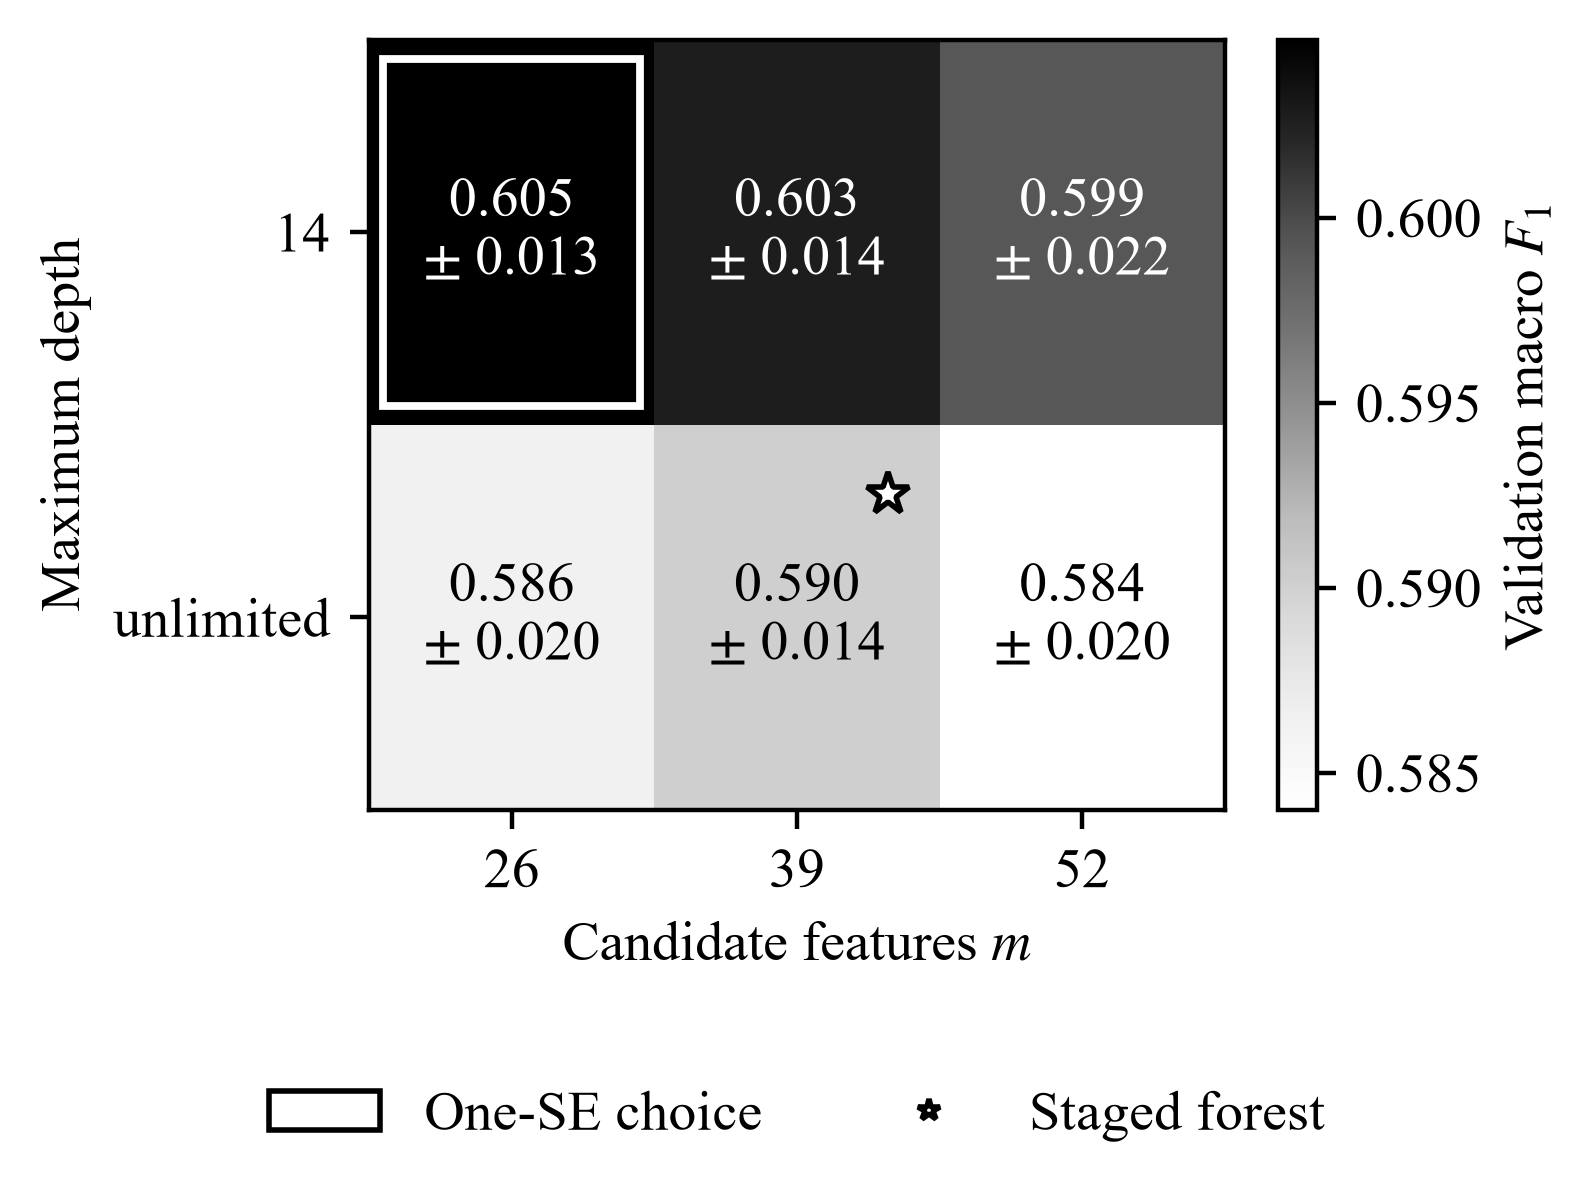

In [ ]:
# Heatmap of the jointly evaluated pairs; annotations show fold mean +- SD.
from matplotlib import patheffects
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

joint_depth_labels = ["unlimited" if depth is None else str(depth) for depth in JOINT_DEPTHS]
joint_means = joint_summary.pivot(index="max_depth", columns="m", values="macro_f1_mean")
joint_stds = joint_summary.pivot(index="max_depth", columns="m", values="macro_f1_std")
joint_means = joint_means.reindex(index=joint_depth_labels, columns=JOINT_M_VALUES)
joint_stds = joint_stds.reindex(index=joint_depth_labels, columns=JOINT_M_VALUES)

joint_fig, joint_ax = plt.subplots(figsize=(3.45, 2.5))
joint_image = joint_ax.imshow(joint_means.to_numpy(), cmap="Greys", aspect="auto")
joint_midpoint = (joint_means.to_numpy().min() + joint_means.to_numpy().max()) / 2
for joint_i, joint_depth_label in enumerate(joint_depth_labels):
    for joint_j, joint_m in enumerate(JOINT_M_VALUES):
        joint_value = joint_means.loc[joint_depth_label, joint_m]
        joint_ax.text(joint_j, joint_i,
                      f"{joint_value:.3f}\n$\\pm$ {joint_stds.loc[joint_depth_label, joint_m]:.3f}",
                      ha="center", va="center",
                      color="white" if joint_value > joint_midpoint else "black")

joint_x = JOINT_M_VALUES.index(JOINT_M)
joint_y = joint_depth_labels.index(str(joint_selected["max_depth"]))
joint_ax.add_patch(plt.Rectangle(
    (joint_x - 0.45, joint_y - 0.45), 0.9, 0.9,
    fill=False, edgecolor="white", linewidth=1.4,
    path_effects=[patheffects.withStroke(linewidth=3.2, foreground="black")],
))
joint_staged_x = JOINT_M_VALUES.index(int(M))
joint_staged_y = joint_depth_labels.index(joint_staged_depth)
joint_ax.plot(joint_staged_x + 0.32, joint_staged_y - 0.32, marker="*", linestyle="none",
              color="white", markeredgecolor="black", markersize=8)
joint_ax.set_xticks(range(len(JOINT_M_VALUES)))
joint_ax.set_xticklabels(JOINT_M_VALUES)
joint_ax.set_yticks(range(len(joint_depth_labels)))
joint_ax.set_yticklabels(joint_depth_labels)
joint_ax.set_xlabel("Candidate features $m$")
joint_ax.set_ylabel("Maximum depth")
joint_ax.grid(False)
joint_fig.colorbar(joint_image, ax=joint_ax, label="Validation macro $F_1$")
joint_ax.legend(handles=[Patch(facecolor="none", edgecolor="black", label="One-SE choice"),
                         Line2D([], [], color="white", marker="*", markeredgecolor="black",
                                linestyle="none", label="Staged forest")],
                loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
joint_fig.savefig("figures/fig_joint_depth_subspace.png", dpi=400, bbox_inches="tight")
plt.show()


In [ ]:
# Check ensemble size again at the joint depth/subspace choice.
q1_joint, q1_joint_classes = ensemble_size_curve(
    lambda y: make_forest(y, n_trees=max(CHECKPOINTS), m=JOINT_M,
                          max_depth=JOINT_MAX_DEPTH, bag=BAG, gamma=GAMMA),
    tune_folds,
)
JOINT_TREES = int(one_se_choice(q1_joint, TUNE_FOLDS))
q1_joint.to_csv("results/q1_trees_joint.csv", index=False)
q1_joint_classes.to_csv("results/q1_oob_classes_joint.csv")
print(q1_joint.round(4).to_string(index=False))
print("Tree count after the joint search:", JOINT_TREES)


def make_final_forest(y_fit, seed=SEED):
    return make_forest(y_fit, n_trees=JOINT_TREES, m=JOINT_M,
                       max_depth=JOINT_MAX_DEPTH, bag=BAG, gamma=GAMMA, seed=seed)


final = {"grouping threshold": MIN_SHARE, "trees": JOINT_TREES, "m": JOINT_M,
         "max depth": JOINT_MAX_DEPTH, "bag": BAG, "gamma": GAMMA}
print("Final forest after the joint search:", final)
pd.Series(final).to_csv("results/final_configuration.csv")


 setting  macro_f1_mean  macro_f1_std  oob_macro_f1_mean  oob_macro_f1_std  oob_scored_mean  oob_scored_std
       1         0.5536        0.0091             0.4925            0.0075           0.4243          0.0009
       2         0.5573        0.0200             0.5071            0.0090           0.6650          0.0010
       5         0.5920        0.0137             0.5303            0.0075           0.9258          0.0006
      10         0.5984        0.0085             0.5557            0.0065           0.9898          0.0004
      20         0.6048        0.0132             0.5733            0.0062           0.9987          0.0001
      50         0.6049        0.0135             0.5866            0.0054           0.9998          0.0000
     100         0.6090        0.0116             0.5913            0.0089           1.0000          0.0000
     150         0.6101        0.0122             0.5941            0.0059           1.0000          0.0000
     200         0.6112     

In [19]:
for name, table in [("max depth", q2_forest), ("m", q3_m), ("bag", q3_bag), ("gamma", q4)]:
    print(f"{name:9s} macro F1 -> {one_se_choice(table, TUNE_FOLDS)} | MCC -> {one_se_choice(table, TUNE_FOLDS, 'mcc')}")

max depth macro F1 -> unlimited | MCC -> 16
m         macro F1 -> 39 | MCC -> 13
bag       macro F1 -> 1.0 | MCC -> 0.5
gamma     macro F1 -> 0.25 | MCC -> 0.0


In [ ]:
for name, table in [("default", q1_default), ("staged", q1_final)]:
    gap = (table["oob_macro_f1_mean"] - table["macro_f1_mean"])[table["setting"] >= 100].mean()
    print(f"{name} forest: OOB minus CV from 100 trees on {gap:+.4f} | the rule picks",
          one_se_choice(table, TUNE_FOLDS), "trees with CV and",
          one_se_choice(table, TUNE_FOLDS, "oob_macro_f1"), "trees with OOB")


q1_classes = pd.concat({"default": q1_default_classes, "staged": q1_final_classes}, axis=1)
print(q1_classes.round(3).to_string())
q1_classes.to_csv("results/q1_oob_classes.csv")

default forest: OOB minus CV from 100 trees on -0.0056 | the rule picks 50 trees with CV and 150 trees with OOB
staged forest: OOB minus CV from 100 trees on -0.0087 | the rule picks 20 trees with CV and 200 trees with OOB
               default                        staged                     
                 cv_f1 oob_f1 left_out_share  cv_f1 oob_f1 left_out_share
Normal           0.923  0.922          0.368  0.923  0.922          0.484
Reconnaissance   0.822  0.824          0.368  0.823  0.821          0.312
Backdoor         0.103  0.101          0.369  0.111  0.118          0.161
DoS              0.310  0.312          0.368  0.365  0.358          0.326
Exploits         0.715  0.716          0.368  0.705  0.705          0.418
Analysis         0.126  0.142          0.367  0.114  0.129          0.172
Fuzzers          0.624  0.620          0.368  0.645  0.641          0.362
Worms            0.315  0.243          0.366  0.645  0.582          0.032
Shellcode        0.598  0.611        

In [ ]:
eval_tree_folds = make_folds(X_eval, y_eval, EVAL_FOLDS, lambda a, b: tree_inputs(a, b, MIN_SHARE))
eval_knn_folds = make_folds(X_eval, y_eval, EVAL_FOLDS, knn_inputs)

cv = {
    "k-NN": run_cv(lambda y: make_knn(), eval_knn_folds, train_scores=True),
    "tree": run_cv(lambda y: make_tree(), eval_tree_folds, train_scores=True),
    "forest": run_cv(make_final_forest, eval_tree_folds, train_scores=True),
}
del eval_tree_folds, eval_knn_folds

cv_table = pd.DataFrame([summarise(cv[name], name) for name in cv])
cols = ["setting", "macro_f1_mean", "macro_f1_std", "mcc_mean", "mcc_std", "accuracy_mean", "accuracy_std",
        "train_macro_f1_mean", "train_macro_f1_std", "fit_time_mean"]
print(cv_table[cols].round(4).to_string(index=False))
cv_table.to_csv("results/cv_comparison.csv", index=False)
for name in cv:
    cv[name].to_csv(f"results/cv_folds_{name}.csv", index=False)

setting  macro_f1_mean  macro_f1_std  mcc_mean  mcc_std  accuracy_mean  accuracy_std  train_macro_f1_mean  train_macro_f1_std  fit_time_mean
   k-NN         0.5349        0.0099    0.7387   0.0018         0.7998        0.0013               0.7620              0.0098         0.0320
   tree         0.5622        0.0173    0.7587   0.0033         0.8144        0.0025               0.6066              0.0222         2.5905
 forest         0.6109        0.0131    0.7688   0.0025         0.8209        0.0020               0.6759              0.0172         8.5989


In [ ]:
def holm(p_values):

    p_values = np.asarray(p_values)
    adjusted = np.empty(len(p_values))
    running_max = 0.0
    for rank, i in enumerate(np.argsort(p_values)):
        running_max = max(running_max, (len(p_values) - rank) * p_values[i])
        adjusted[i] = min(1.0, running_max)
    return adjusted


def corrected_t_test(scores_a, scores_b, n_folds=EVAL_FOLDS):


    d = np.asarray(scores_a) - np.asarray(scores_b)
    t = d.mean() / np.sqrt((1 / n_folds + 1 / (n_folds - 1)) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), df=n_folds - 1)


tests = []
pairs = [("forest", "tree"), ("forest", "k-NN"), ("tree", "k-NN")]
for measure in ["macro_f1", "mcc"]:
    results = [corrected_t_test(cv[a][measure], cv[b][measure]) for a, b in pairs]
    for (a, b), (t, p_raw), p_holm in zip(pairs, results, holm([p for _, p in results])):
        wins = int(np.sum(cv[a][measure] > cv[b][measure]))
        tests.append({"measure": measure, "pair": f"{a} vs {b}", "folds_won_by_first": wins,
                      "t": t, "p": p_raw, "holm_p": p_holm})
tests = pd.DataFrame(tests)
print(tests.to_string(index=False))
tests.to_csv("results/cv_tests.csv", index=False)

 measure           pair  folds_won_by_first         t            p       holm_p
macro_f1 forest vs tree                  10  7.348268 4.335289e-05 8.670578e-05
macro_f1 forest vs k-NN                  10 11.476212 1.125094e-06 3.375282e-06
macro_f1   tree vs k-NN                   8  2.791066 2.101719e-02 2.101719e-02
     mcc forest vs tree                  10  7.189201 5.142941e-05 5.142941e-05
     mcc forest vs k-NN                  10 26.586499 7.285168e-10 2.185550e-09
     mcc   tree vs k-NN                  10 15.812502 7.128910e-08 1.425782e-07


In [ ]:
A_dev, B_test = tree_inputs(X_dev, X_test, MIN_SHARE)
A_dev_knn, B_test_knn = knn_inputs(X_dev, X_test)


def fit_and_predict(model, train_inputs, train_labels, test_inputs):
    start = time.time()
    model.fit(train_inputs, train_labels)
    fit_time = time.time() - start

    start = time.time()
    predictions = model.predict(test_inputs)
    predict_time = time.time() - start
    return predictions, fit_time, predict_time


def test_row(name, pred, fit_time, predict_time):
    attack = y_test != NORMAL
    return {
        "model": name,
        **scores(y_test, pred),
        "missed_attacks": np.mean(pred[attack] == NORMAL),
        "false_alarms": np.mean(pred[~attack] != NORMAL),
        "fit_time": fit_time,
        "predict_time": predict_time,
    }


test_rows, test_pred = [], {}
for name, model, train_inputs, test_inputs in [
    ("k-NN", make_knn(), A_dev_knn, B_test_knn),
    ("tree", make_tree(), A_dev, B_test),
]:
    predictions, fit_time, predict_time = fit_and_predict(
        model, train_inputs, y_dev, test_inputs
    )
    test_pred[name] = predictions
    test_rows.append(test_row(name, predictions, fit_time, predict_time))

forest_runs, forest_preds = [], []
for run in range(TEST_RUNS):
    model = make_final_forest(y_dev, seed=SEED + run)
    predictions, fit_time, predict_time = fit_and_predict(model, A_dev, y_dev, B_test)
    if run == 0:
        test_pred["forest"] = predictions
    forest_runs.append(test_row("forest", predictions, fit_time, predict_time))
    forest_preds.append(predictions)
forest_runs = pd.DataFrame(forest_runs)
forest_runs.to_csv("results/test_forest_runs.csv", index=False)

test_table = pd.DataFrame(test_rows)
forest_mean = forest_runs.drop(columns="model").mean()
forest_std = forest_runs.drop(columns="model").std(ddof=1)
test_table = pd.concat([test_table, pd.DataFrame([{"model": "forest (mean of 10 runs)", **forest_mean},
                                                  {"model": "forest (std of 10 runs)", **forest_std}])])
cols = ["model", "macro_f1", "mcc", "accuracy", "macro_precision", "macro_recall",
        "missed_attacks", "false_alarms", "fit_time", "predict_time"]
print(test_table[cols].round(4).to_string(index=False))
test_table.to_csv("results/test_results.csv", index=False)

                   model  macro_f1    mcc  accuracy  macro_precision  macro_recall  missed_attacks  false_alarms  fit_time  predict_time
                    k-NN    0.5744 0.7461    0.8052           0.6516        0.5526          0.0637        0.0805    0.0523       10.8851
                    tree    0.5840 0.7641    0.8185           0.7222        0.5714          0.0656        0.0630    3.2271        0.0045
forest (mean of 10 runs)    0.6107 0.7727    0.8244           0.6596        0.6141          0.0450        0.0776   13.8402        0.0533
 forest (std of 10 runs)    0.0025 0.0008    0.0006           0.0065        0.0031          0.0010        0.0008    0.4384        0.0041


In [ ]:
def mcnemar(y_true, pred_a, pred_b):

    only_a = np.sum((pred_a == y_true) & (pred_b != y_true))
    only_b = np.sum((pred_a != y_true) & (pred_b == y_true))
    statistic = (abs(only_a - only_b) - 1) ** 2 / (only_a + only_b)
    return only_a, only_b, statistic, stats.chi2.sf(statistic, df=1)


mc = []
for a, b in pairs:
    only_a, only_b, statistic, p = mcnemar(y_test, test_pred[a], test_pred[b])
    mc.append({"pair": f"{a} vs {b}", "only_first_correct": only_a, "only_second_correct": only_b,
               "chi2": statistic, "p_value": p})
mc = pd.DataFrame(mc)
print(mc.to_string(index=False))
mc.to_csv("results/test_mcnemar.csv", index=False)

          pair  only_first_correct  only_second_correct      chi2      p_value
forest vs tree                 942                  807 10.266438 1.354721e-03
forest vs k-NN                1506                 1104 61.609579 4.187765e-15
  tree vs k-NN                1558                 1291 24.835381 6.244080e-07


In [ ]:
per_class = pd.DataFrame({
    "class": CLASS_NAMES,
    "test_count": np.bincount(y_test, minlength=N_CLASSES),
    "conflicting_share": attainable["conflicting_share"],
    "attainable_f1": attainable["attainable_f1"],
    "knn_f1": [test_rows[0]["f1_" + c] for c in CLASS_NAMES],
    "tree_f1": [test_rows[1]["f1_" + c] for c in CLASS_NAMES],
    "forest_f1": [forest_runs["f1_" + c].mean() for c in CLASS_NAMES],
    "forest_f1_std": [forest_runs["f1_" + c].std(ddof=1) for c in CLASS_NAMES],
})
print(per_class.round(3).to_string(index=False))
per_class.to_csv("results/test_per_class.csv", index=False)


cm = confusion_matrix(y_test, test_pred["forest"], labels=range(N_CLASSES), normalize="true")
cm_table = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
cm_table.round(3).to_csv("results/test_confusion_forest.csv")
print(cm_table.round(2).to_string())

         class  test_count  conflicting_share  attainable_f1  knn_f1  tree_f1  forest_f1  forest_f1_std
        Normal        7218              0.010          0.996   0.905    0.913      0.921          0.001
Reconnaissance        1086              0.161          0.914   0.814    0.827      0.835          0.002
      Backdoor         181              0.849          0.265   0.139    0.121      0.140          0.005
           DoS        1269              0.774          0.539   0.375    0.276      0.441          0.003
      Exploits        3456              0.371          0.812   0.695    0.725      0.726          0.001
      Analysis         208              0.770          0.375   0.241    0.107      0.137          0.011
       Fuzzers        1882              0.149          0.924   0.574    0.568      0.632          0.004
         Worms          14              0.086          0.957   0.538    0.690      0.617          0.014
     Shellcode         117              0.009          0.996   0

In [ ]:
pred = test_pred["forest"]
FUZZERS = CLASS_NAMES.index("Fuzzers")
attack = y_test != NORMAL
errors = pred != y_test
missed = attack & (pred == NORMAL)
alarms = ~attack & (pred != NORMAL)
between = errors & attack & (pred != NORMAL)
print("errors:", errors.sum(), f"| between two attack classes: {100 * between.sum() / errors.sum():.1f} %")
print("missed attacks:", missed.sum(), f"| Fuzzers records: {100 * np.mean(y_test[missed] == FUZZERS):.1f} %")
print("false alarms:", alarms.sum(), f"| predicted as Fuzzers: {100 * np.mean(pred[alarms] == FUZZERS):.1f} %")

errors: 3495 | between two attack classes: 67.6 %
missed attacks: 577 | Fuzzers records: 79.0 %
false alarms: 554 | predicted as Fuzzers: 88.4 %


In [ ]:
new = ~test_vectors.isin(dev_vectors).to_numpy()
print("repeated test observations:", (~new).sum(), f"({100 * np.mean(~new):.1f} %)")
print("share of the conflicting test observations that are repeated:",
      f"{100 * np.mean(~new[conflicting[X_test.index]]):.1f} %")


def macro_f1_on(mask, pred):

    return f1_score(y_test[mask], pred[mask], average="macro", labels=np.unique(y_test[mask]), zero_division=0)


rows = []
for name, preds in [("k-NN", [test_pred["k-NN"]]), ("tree", [test_pred["tree"]]), ("forest", forest_preds)]:
    rows.append({"model": name,
                 "macro_f1_new": np.mean([macro_f1_on(new, p) for p in preds]),
                 "macro_f1_repeated": np.mean([macro_f1_on(~new, p) for p in preds])})
new_table = pd.DataFrame(rows)
print(new_table.round(4).to_string(index=False))
new_table.to_csv("results/test_new_vectors.csv", index=False)

repeated test observations: 9283 (46.4 %)
share of the conflicting test observations that are repeated: 99.8 %
 model  macro_f1_new  macro_f1_repeated
  k-NN        0.6236             0.5645
  tree        0.6561             0.5410
forest        0.6921             0.5848


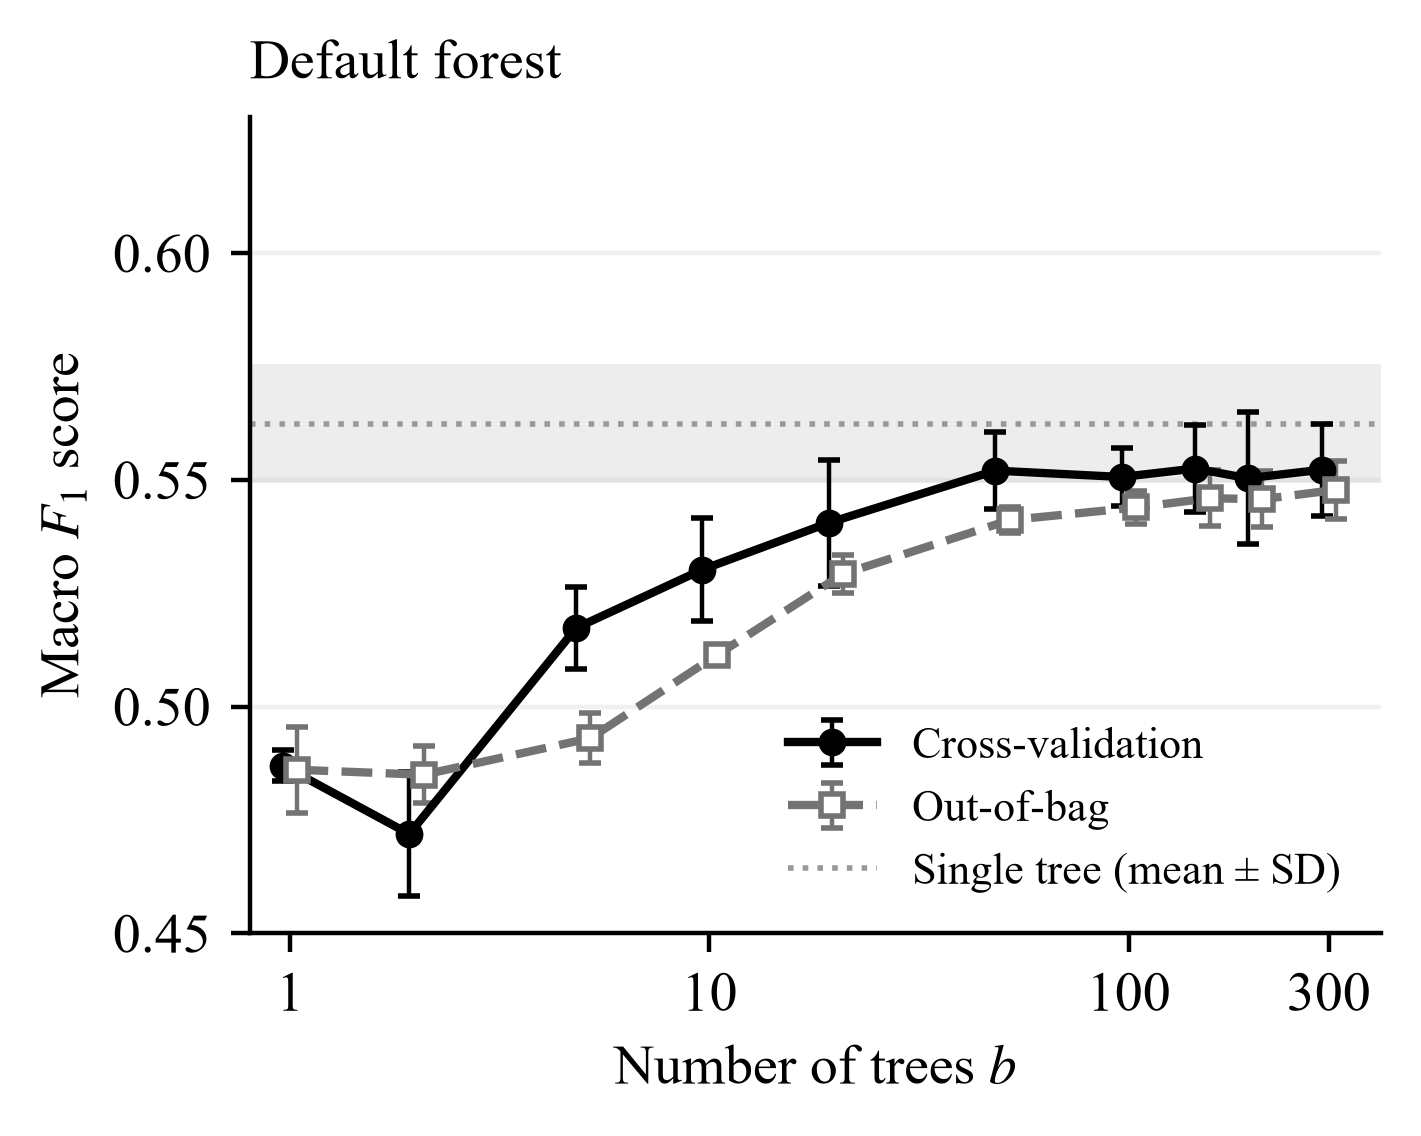

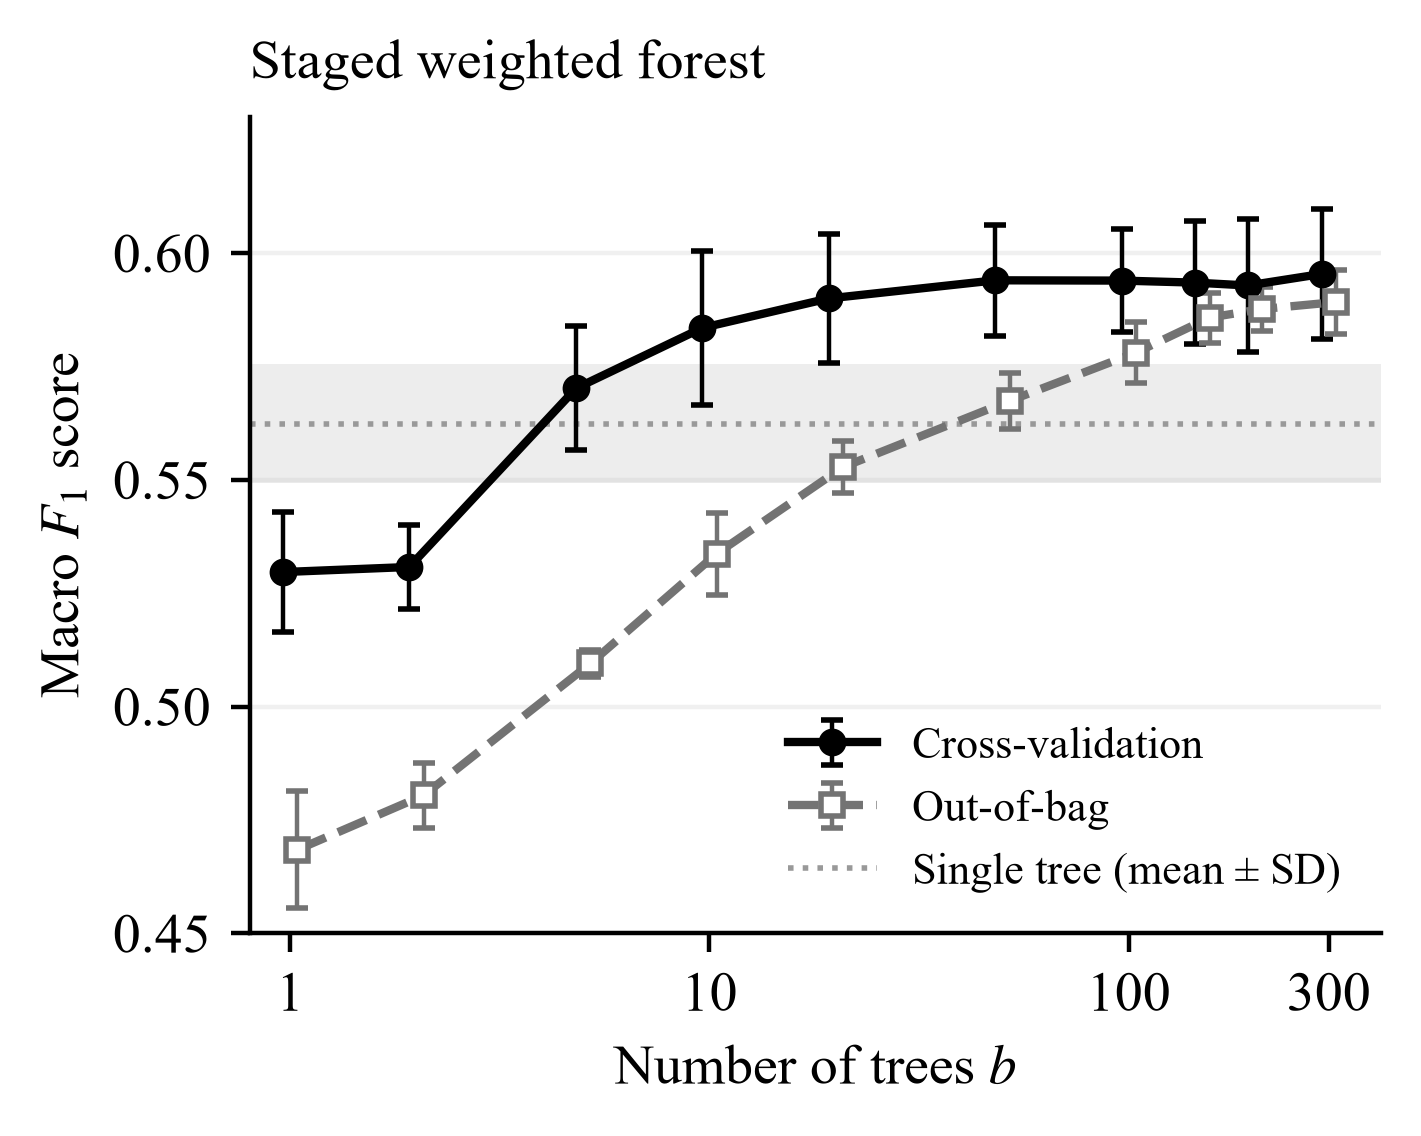

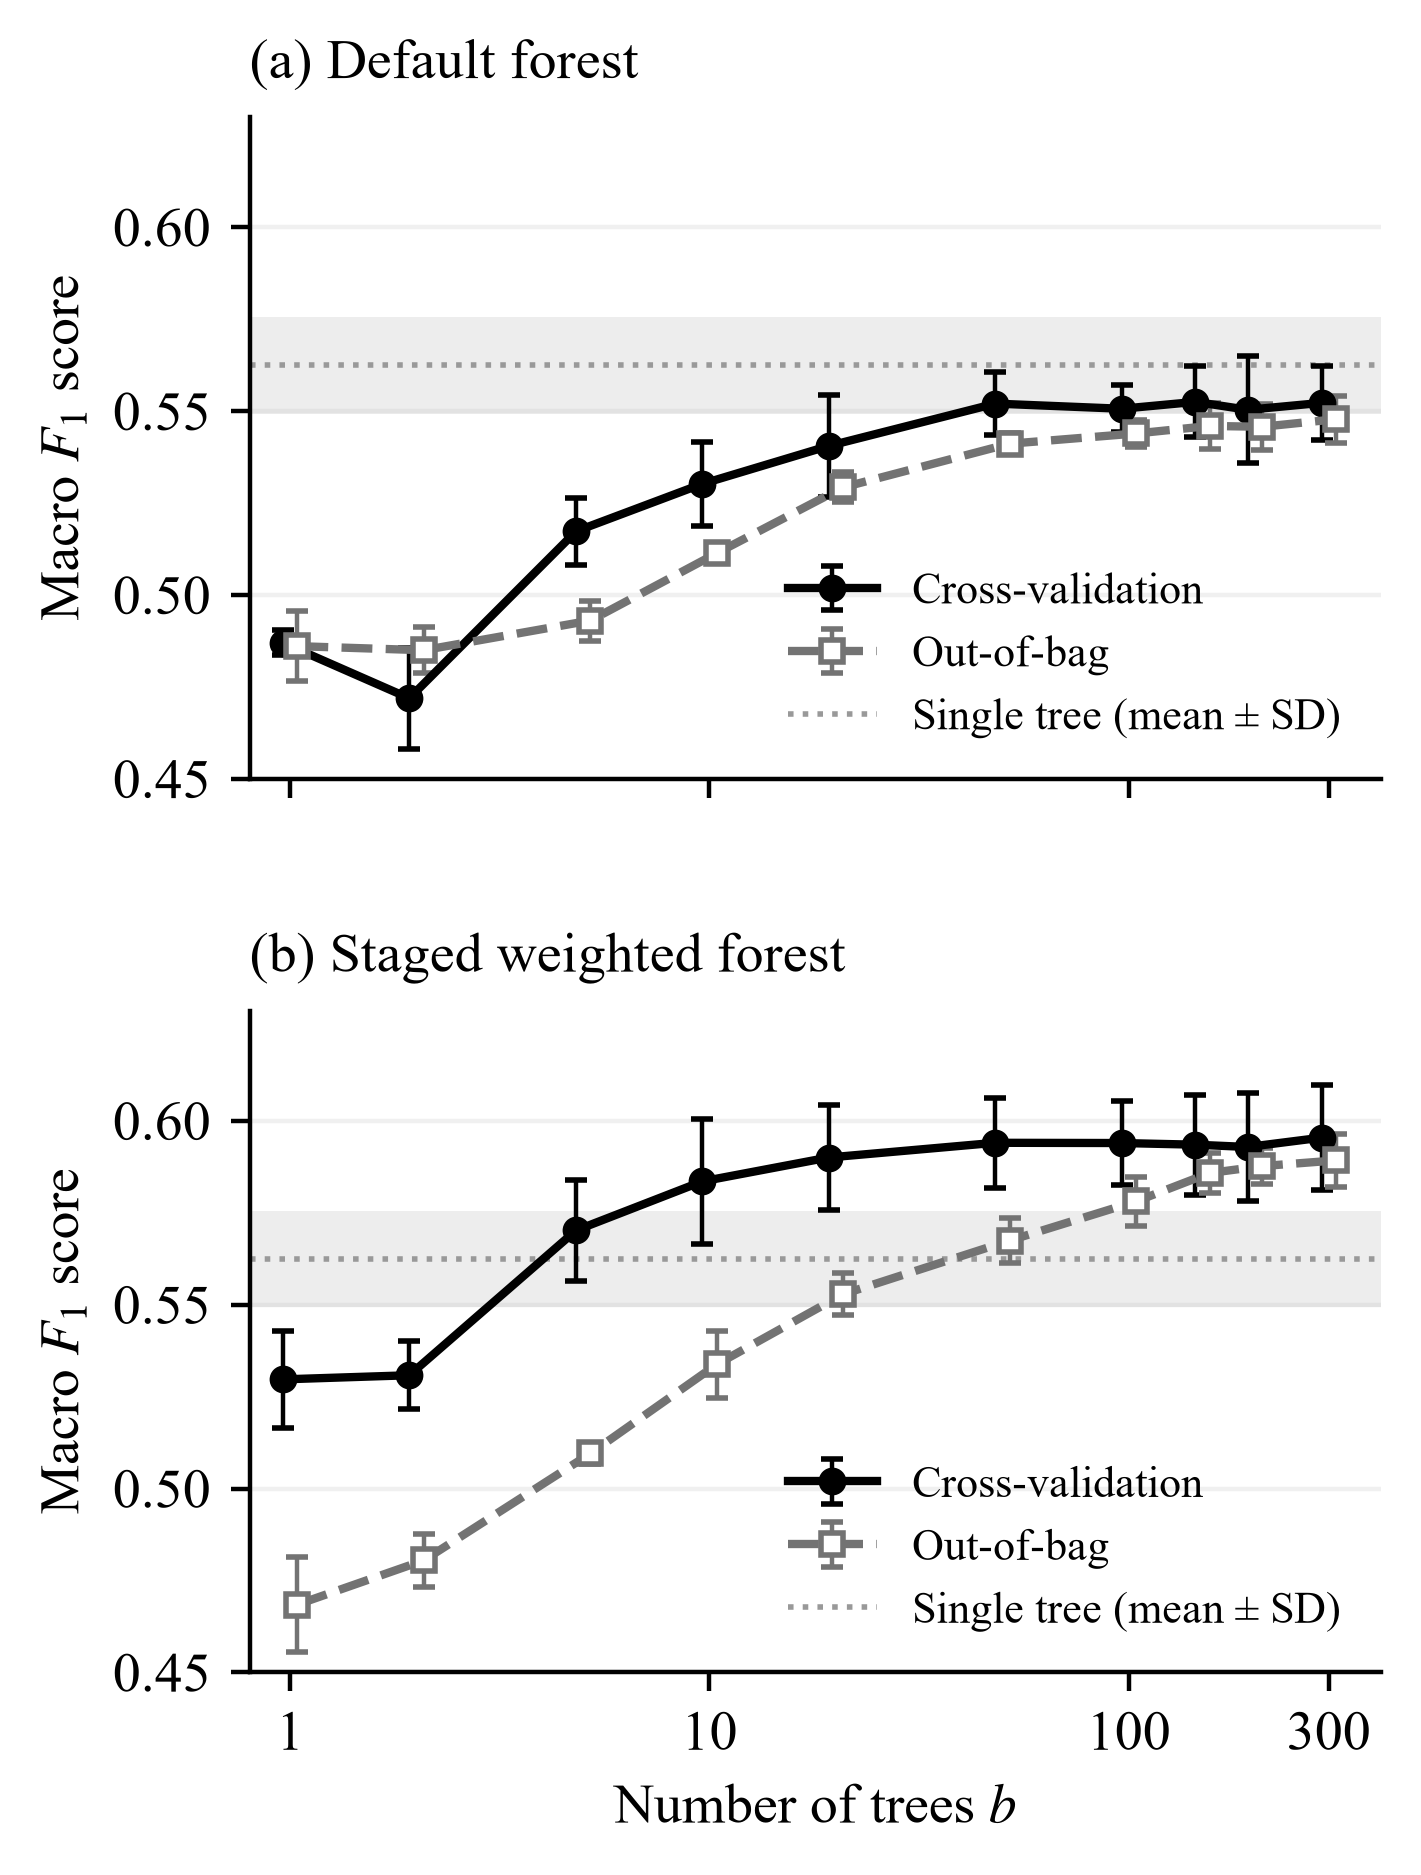

In [ ]:
def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=400, bbox_inches="tight")
    plt.show()


def ref_band(ax, values, colour, label):
    mean, std = np.mean(values), np.std(values, ddof=1)
    ax.axhspan(mean - std, mean + std, color="0.93", linewidth=0, zorder=0)
    ax.axhline(mean, color=colour, linewidth=1, linestyle=":", label=label)


def ensemble_size_panel(ax, table, title):
    ref_band(ax, tree_ref["macro_f1"], "0.60", "Single tree (mean \u00b1 SD)")
    ax.errorbar(
        table["setting"] / 1.04,
        table["macro_f1_mean"],
        yerr=table["macro_f1_std"],
        color="black", marker="o", capsize=2, elinewidth=0.8,
        label="Cross-validation",
    )
    ax.errorbar(
        table["setting"] * 1.04,
        table["oob_macro_f1_mean"],
        yerr=table["oob_macro_f1_std"],
        color="0.45", marker="s", markerfacecolor="white",
        linestyle="--", capsize=2, elinewidth=0.8,
        label="Out-of-bag",
    )
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks([1, 10, 100, max(CHECKPOINTS)])
    ax.set_xticklabels(["1", "10", "100", str(max(CHECKPOINTS))])
    ax.set_xlim(0.8, 400)
    ax.set_ylim(0.45, 0.63)
    ax.set_yticks([0.45, 0.50, 0.55, 0.60])
    ax.set_title(title, loc="left", fontsize=10, pad=7)
    ax.set_ylabel("Macro $F_1$ score")
    ax.grid(False)
    ax.yaxis.grid(True, alpha=0.18)
    ax.spines[["top", "right"]].set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    order = [1, 2, 0]
    ax.legend(
        [handles[i] for i in order], [labels[i] for i in order],
        loc="lower right", frameon=False, fontsize=8,
    )


for table, title, filename in [
    (q1_default, "Default forest", "fig_trees_oob_default"),
    (q1_final, "Staged weighted forest", "fig_trees_oob_staged"),
]:
    fig, ax = plt.subplots(figsize=(3.65, 2.65))
    ensemble_size_panel(ax, table, title)
    ax.set_xlabel("Number of trees $b$")
    save(fig, filename)

fig, axes = plt.subplots(2, 1, figsize=(3.65, 5.05), sharex=True, sharey=True)
ensemble_size_panel(axes[0], q1_default, "(a) Default forest")
ensemble_size_panel(axes[1], q1_final, "(b) Staged weighted forest")
axes[1].set_xlabel("Number of trees $b$")
fig.subplots_adjust(hspace=0.35)
save(fig, "fig_trees_oob")


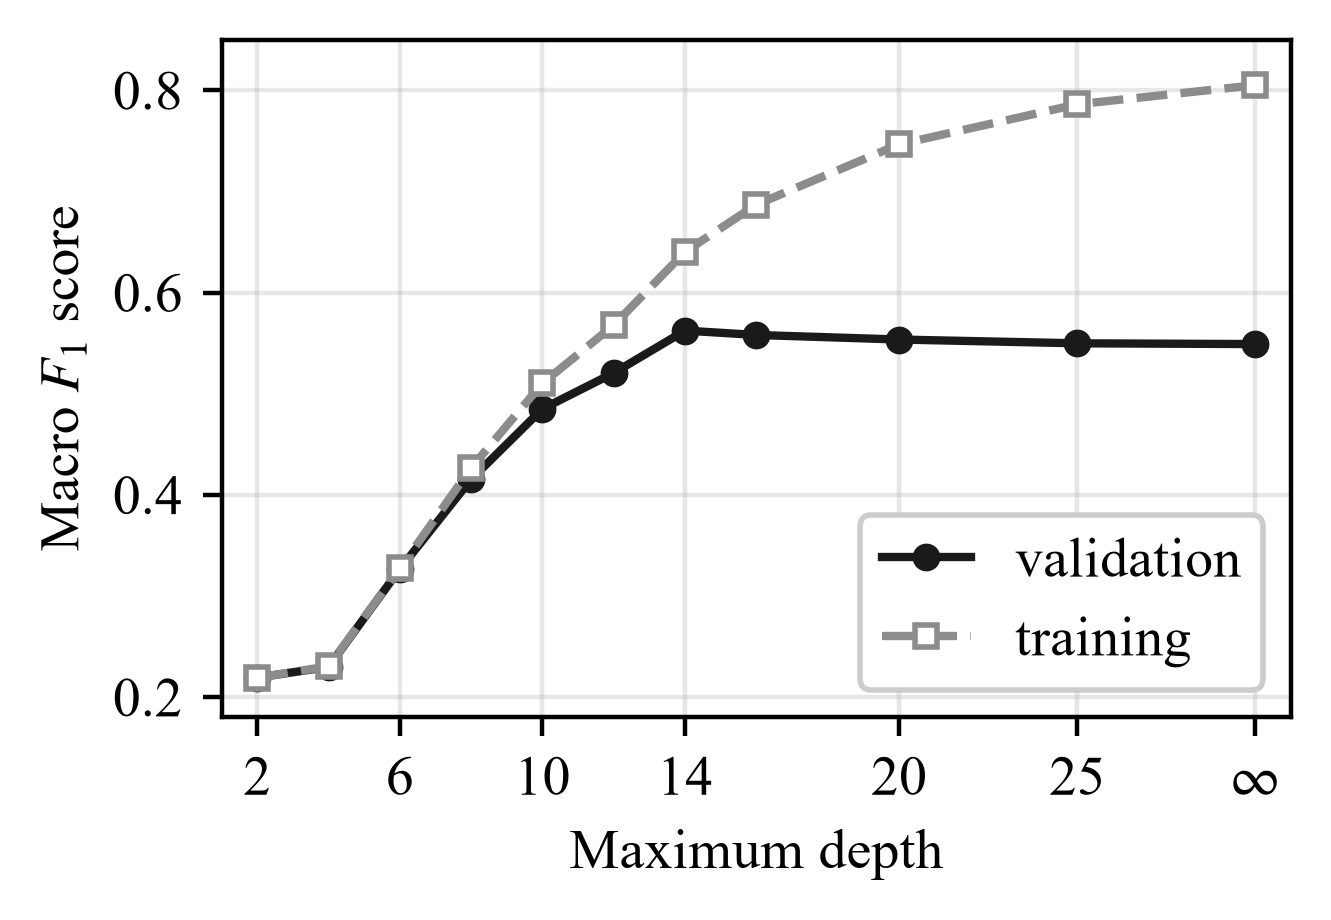

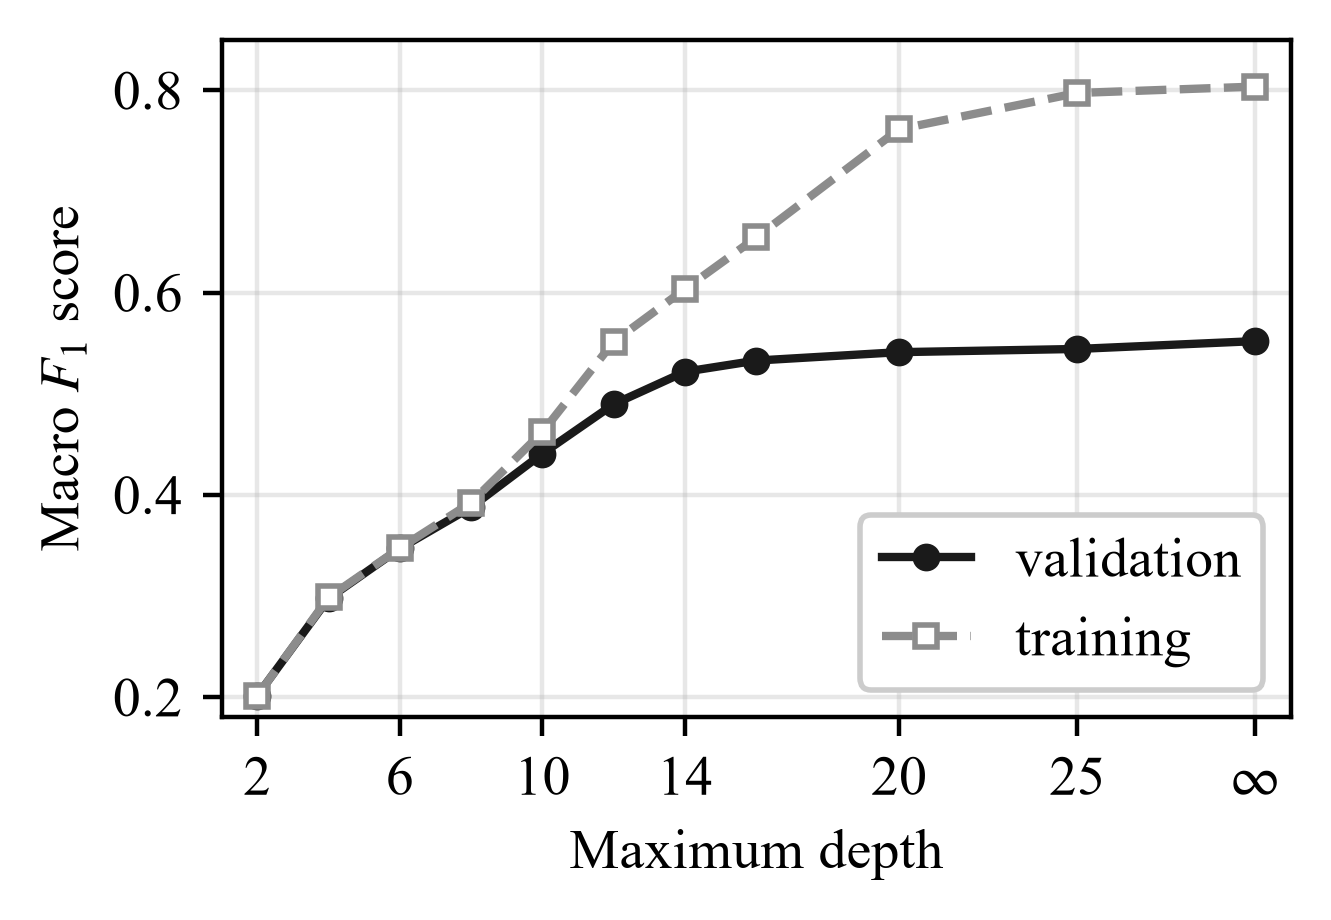

In [ ]:
for table, filename in [(q2_tree, "fig_depth_tree"), (q2_forest, "fig_depth_forest")]:
    positions = [30.0 if depth == "unlimited" else float(depth) for depth in table["setting"]]
    fig, ax = plt.subplots(figsize=(3.45, 2.2))
    ax.plot(positions, table["macro_f1_mean"], color=COLOURS["forest"], marker="o",
            label="validation")
    ax.plot(positions, table["train_macro_f1_mean"], color=COLOURS["tree"], marker="s",
            linestyle="--", markerfacecolor="white", label="training")
    ax.set_xticks([2, 6, 10, 14, 20, 25, 30])
    ax.set_xticklabels(["2", "6", "10", "14", "20", "25", r"$\infty$"])
    ax.set_xlim(1, 31)
    ax.set_ylim(0.18, 0.85)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8])
    ax.set_xlabel("Maximum depth")
    ax.set_ylabel("Macro $F_1$ score")
    ax.legend(loc="lower right", framealpha=1, handlelength=1.6)
    save(fig, filename)

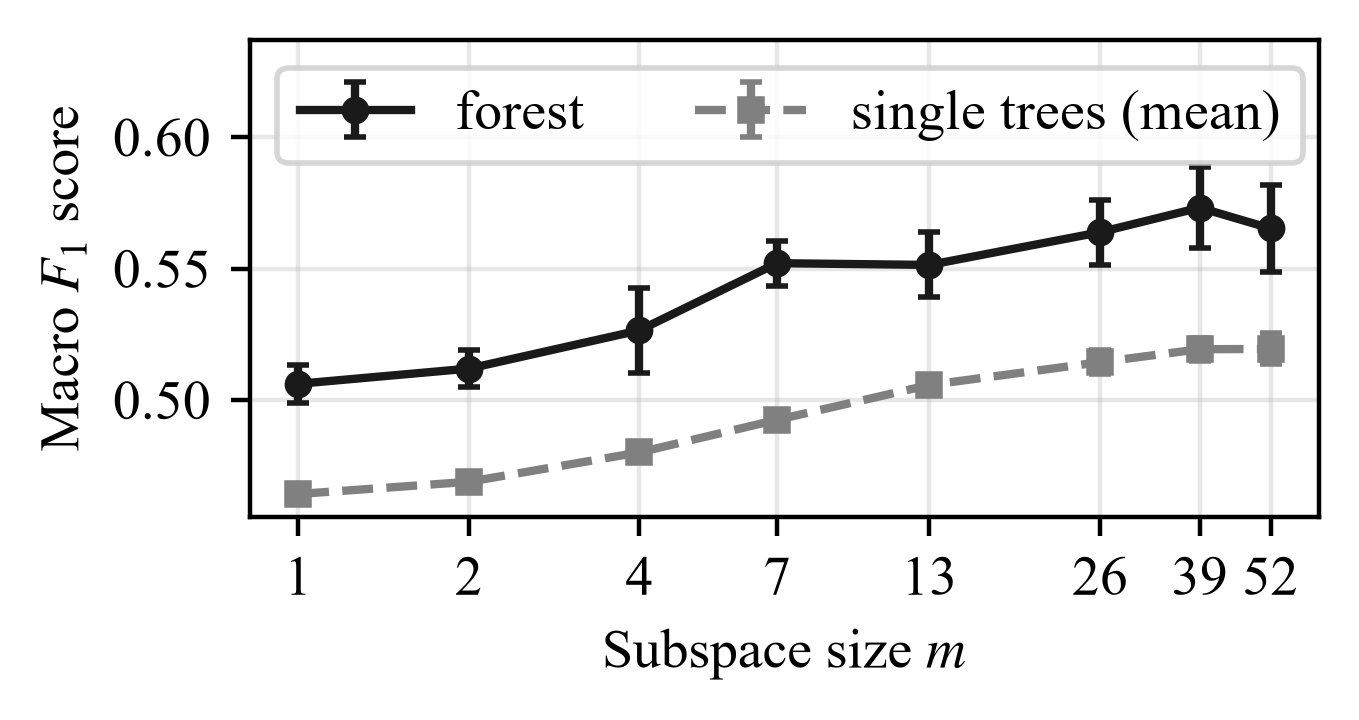

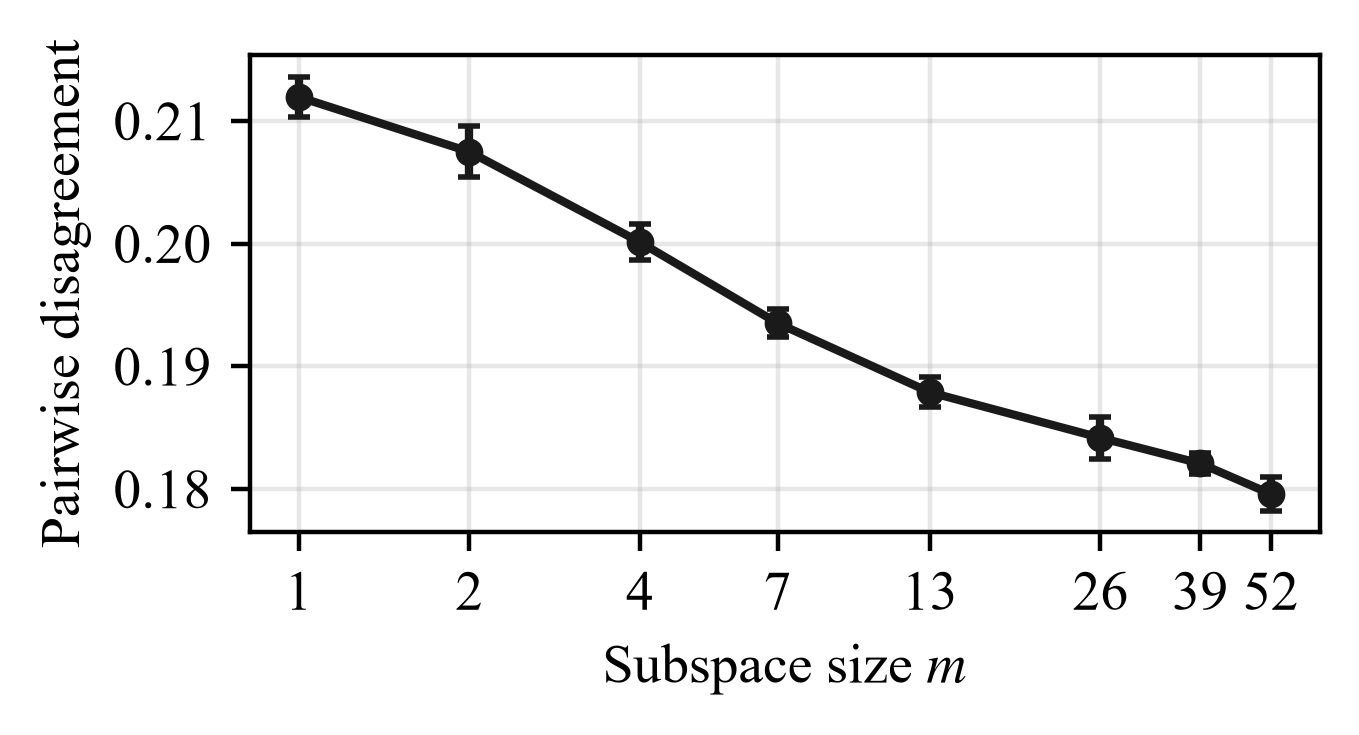

In [29]:
fig, ax = plt.subplots(figsize=(3.45, 1.55))
ax.errorbar(q3_m["setting"], q3_m["macro_f1_mean"], yerr=q3_m["macro_f1_std"], color=COLOURS["forest"],
            marker="o", capsize=2, label="forest")
ax.errorbar(q3_m["setting"], q3_m["strength_mean"], yerr=q3_m["strength_std"], color=COLOURS["grey"],
            marker="s", linestyle="--", capsize=2, label="single trees (mean)")
ax.set_xscale("log", base=2)
ax.minorticks_off()
ax.set_xticks(M_VALUES)
ax.set_xticklabels([str(m) for m in M_VALUES])
ax.set_xlabel("Subspace size $m$")
ax.set_ylabel("Macro $F_1$ score")
bottom, top = ax.get_ylim()
ax.set_ylim(bottom, top + 0.3 * (top - bottom))
ax.legend(loc="upper left", ncol=2)
save(fig, "fig_subspace_f1")

fig, ax = plt.subplots(figsize=(3.45, 1.55))
ax.errorbar(q3_m["setting"], q3_m["disagreement_mean"], yerr=q3_m["disagreement_std"],
            color=COLOURS["forest"], marker="o", capsize=2)
ax.set_xscale("log", base=2)
ax.minorticks_off()
ax.set_xticks(M_VALUES)
ax.set_xticklabels([str(m) for m in M_VALUES])
ax.set_xlabel("Subspace size $m$")
ax.set_ylabel("Pairwise disagreement")
save(fig, "fig_subspace_div")

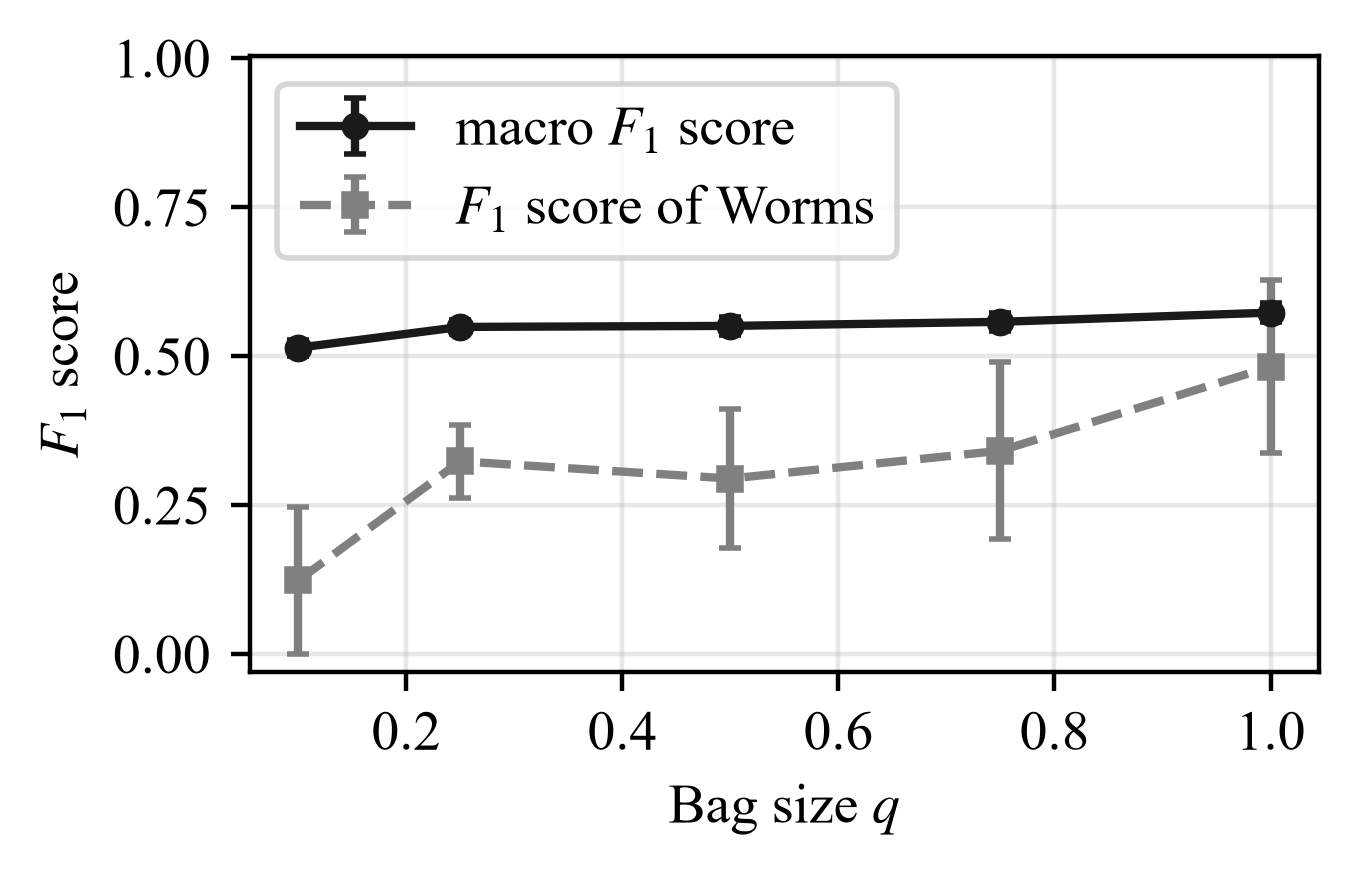

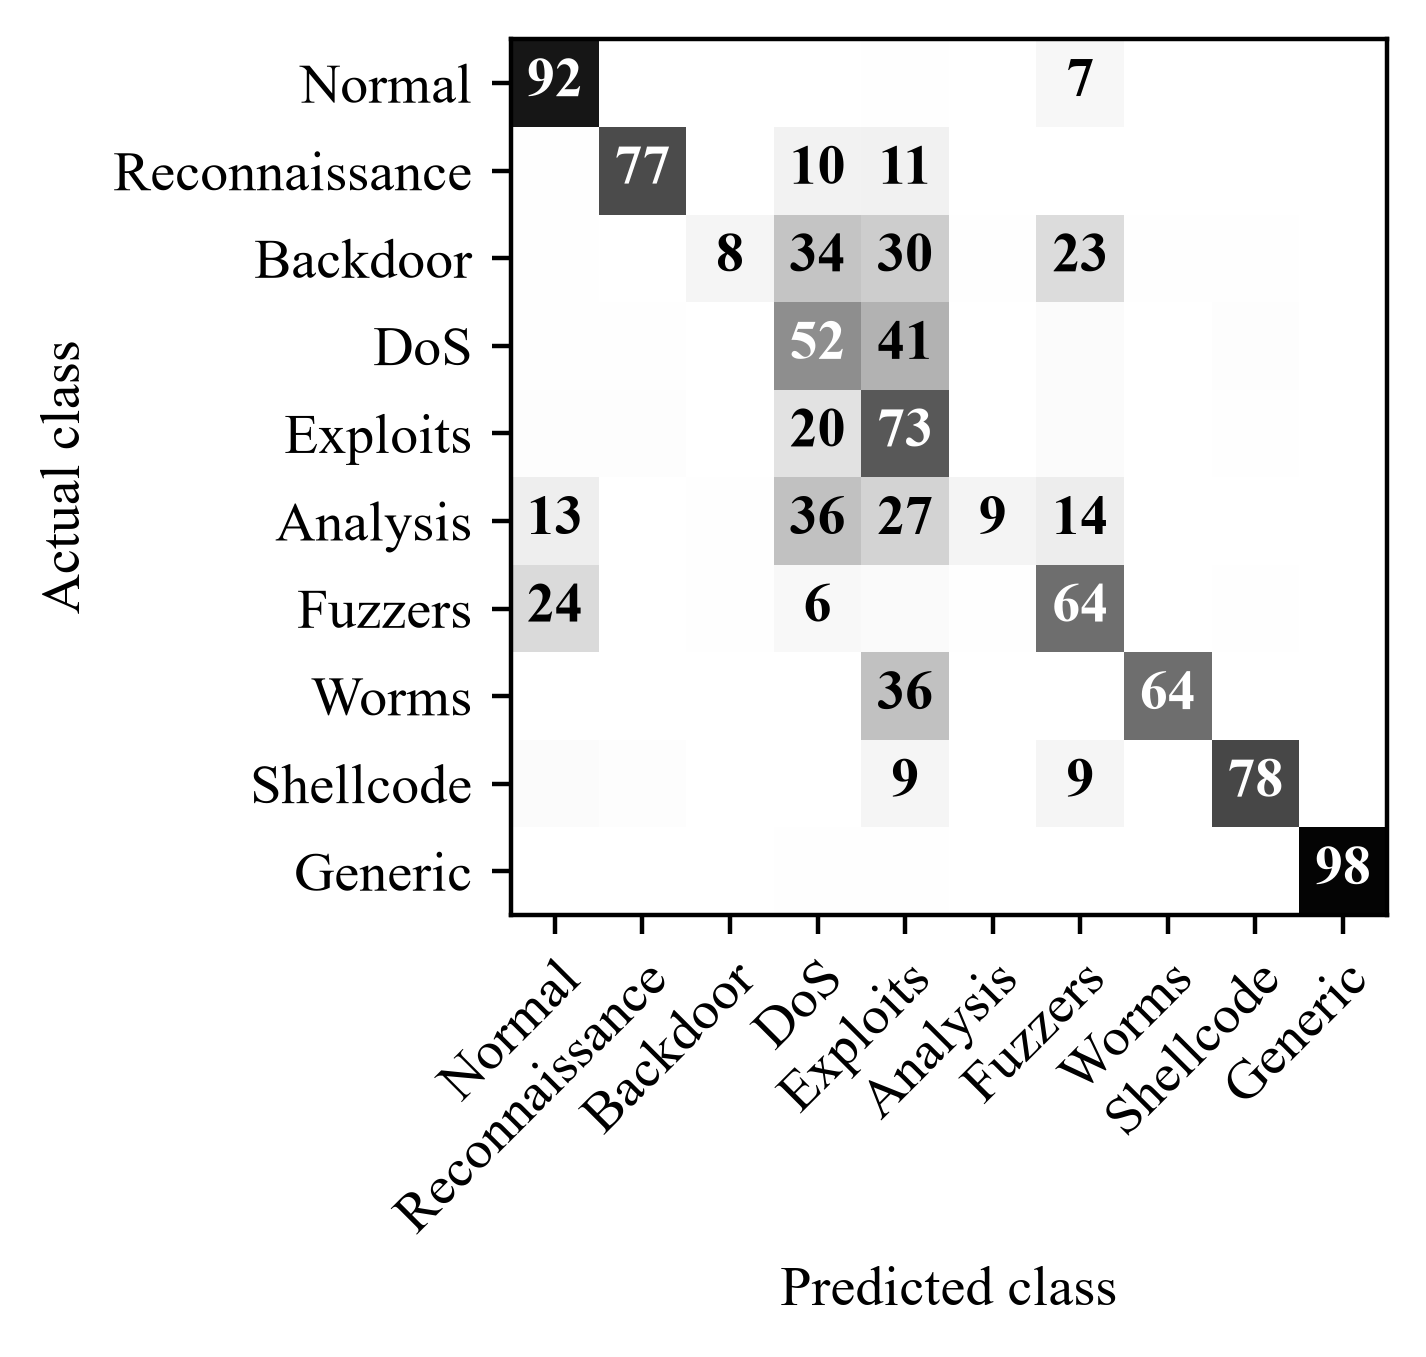

In [30]:
fig, ax = plt.subplots(figsize=(3.45, 2.0))
ax.errorbar(q3_bag["setting"], q3_bag["macro_f1_mean"], yerr=q3_bag["macro_f1_std"],
            color=COLOURS["forest"], marker="o", capsize=2, label="macro $F_1$ score")
ax.errorbar(q3_bag["setting"], q3_bag["f1_Worms_mean"], yerr=q3_bag["f1_Worms_std"],
            color=COLOURS["grey"], marker="s", linestyle="--", capsize=2, label="$F_1$ score of Worms")
ax.set_xlabel("Bag size $q$")
ax.set_ylabel("$F_1$ score")
bottom, top = ax.get_ylim()
ax.set_ylim(bottom, top + 0.5 * (top - bottom))
ax.legend(loc="upper left")
save(fig, "fig_bag")


fig, ax = plt.subplots(figsize=(3.45, 3.35), layout="constrained")
ax.imshow(cm, cmap="Greys", vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(N_CLASSES))
ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", rotation_mode="anchor")
ax.set_yticklabels(CLASS_NAMES)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{100 * cm[i, j]:.0f}", ha="center", va="center", fontweight="bold",
                    color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
save(fig, "fig_confusion")